In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.sparse import csr_matrix
from scipy import sparse
from collections import Counter

In [2]:

# Dataset directory
data_dir = Path.home() / "Downloads" / "GSE157783"

# File paths
umi_file = data_dir / "IPDCO_hg_midbrain_UMI.tsv"
genes_file = data_dir / "IPDCO_hg_midbrain_genes.tsv"
cells_file = data_dir / "IPDCO_hg_midbrain_cell.tsv"

# 1. Verify files exist
files = {
    "UMI matrix": umi_file,
    "Gene metadata": genes_file,
    "Cell metadata": cells_file
}

for name, path in files.items():
    if path.exists():
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"FOUND: {name} | {size_mb:.2f} MB | {path}")
    else:
        print(f"MISSING: {name} | {path}")

# 2. Inspect gene and cell metadata
if genes_file.exists():
    genes_preview = pd.read_csv(genes_file, sep="\t", nrows=5)
    print("\nGENE METADATA")
    print("Columns:", genes_preview.columns.tolist())
    display(genes_preview)

if cells_file.exists():
    cells_preview = pd.read_csv(cells_file, sep="\t", nrows=5)
    print("\nCELL METADATA")
    print("Columns:", cells_preview.columns.tolist())
    display(cells_preview)

# 3. Inspect the UMI matrix header only.
# This does NOT load the 2 GB expression matrix.
if umi_file.exists():
    umi_header = pd.read_csv(umi_file, sep="\t", nrows=0)
    print("\nUMI MATRIX")
    print("Number of columns:", len(umi_header.columns))
    print("First 10 column names:", umi_header.columns[:10].tolist())

FOUND: UMI matrix | 2118.07 MB | C:\Users\LENOVO\Downloads\GSE157783\IPDCO_hg_midbrain_UMI.tsv
FOUND: Gene metadata | 2.59 MB | C:\Users\LENOVO\Downloads\GSE157783\IPDCO_hg_midbrain_genes.tsv
FOUND: Cell metadata | 1.52 MB | C:\Users\LENOVO\Downloads\GSE157783\IPDCO_hg_midbrain_cell.tsv

GENE METADATA
Columns: ['gene', 'row', 'vst.mean', 'vst.variance', 'vst.variance.expected', 'vst.variance.standardized', 'vst.variable']


,gene,row,vst.mean,vst.variance,vst.variance.expected,vst.variance.standardized,vst.variable
0,ENSG00000238009,1,0.042500,0.045715,0.062704,0.729062,False
1,ENSG00000235146,2,0.002124,0.002119,0.002382,0.889805,False
2,ENSG00000237491,3,0.322143,0.589951,0.658533,0.895857,False
3,ENSG00000225880,4,0.009268,0.009423,0.011610,0.811670,False
4,ENSG00000230368,5,0.002655,0.002744,0.003012,0.911060,False



CELL METADATA
Columns: ['barcode', 'cell_ontology', 'patient']


,barcode,cell_ontology,patient
0,AAACCCACACATTGTG-1_1,Oligodendrocytes,PD3
1,AAACCCAGTAAGATTG-1_1,Excitatory,PD3
2,AAACGAACACCGCTGA-1_1,Oligodendrocytes,PD3
3,AAACGAAGTGCTTATG-1_1,Microglia,PD3
4,AAACGAATCAATCTCT-1_1,Oligodendrocytes,PD3



UMI MATRIX
Number of columns: 41435
First 10 column names: ['AAACCCACACATTGTG-1_1', 'AAACCCAGTAAGATTG-1_1', 'AAACGAACACCGCTGA-1_1', 'AAACGAAGTGCTTATG-1_1', 'AAACGAATCAATCTCT-1_1', 'AAACGAATCCAGTGCG-1_1', 'AAACGCTAGACTCTTG-1_1', 'AAACGCTAGCGACCCT-1_1', 'AAACGCTCACCTATCC-1_1', 'AAACGCTGTCTAACGT-1_1']


In [3]:

# Load metadata
genes = pd.read_csv(genes_file, sep="\t")
cells = pd.read_csv(cells_file, sep="\t")

print("GENE METADATA")
print("Shape:", genes.shape)
print("Columns:", genes.columns.tolist())
print("Unique gene IDs:", genes["gene"].nunique())

print("\nCELL METADATA")
print("Shape:", cells.shape)
print("Columns:", cells.columns.tolist())
print("Unique barcodes:", cells["barcode"].nunique())
print("Missing values:\n", cells.isna().sum())

# Inspect donor IDs before assigning disease labels
print("\nDONORS FOUND")
print(sorted(cells["patient"].dropna().unique()))

print("\nNUCLEI PER DONOR")
display(
    cells.groupby("patient")
    .agg(
        total_nuclei=("barcode", "size"),
        cell_types=("cell_ontology", "nunique")
    )
    .sort_index()
)

print("\nNUCLEI PER CELL TYPE")
display(
    cells["cell_ontology"]
    .value_counts()
    .rename_axis("cell_type")
    .reset_index(name="n_nuclei")
)

# Check barcode uniqueness
print("\nDuplicate metadata barcodes:",
      cells["barcode"].duplicated().sum())

# Compare metadata barcodes against the expression matrix header
umi_header = pd.read_csv(umi_file, sep="\t", nrows=0)
matrix_barcodes = pd.Index(umi_header.columns.astype(str))
metadata_barcodes = pd.Index(cells["barcode"].astype(str))

print("\nBARCODE MATCHING")
print("Matrix barcodes:", len(matrix_barcodes))
print("Metadata barcodes:", len(metadata_barcodes))
print("Matrix barcodes missing from metadata:",
      len(matrix_barcodes.difference(metadata_barcodes)))
print("Metadata barcodes missing from matrix:",
      len(metadata_barcodes.difference(matrix_barcodes)))

GENE METADATA
Shape: (26737, 7)
Columns: ['gene', 'row', 'vst.mean', 'vst.variance', 'vst.variance.expected', 'vst.variance.standardized', 'vst.variable']
Unique gene IDs: 26737

CELL METADATA
Shape: (41435, 3)
Columns: ['barcode', 'cell_ontology', 'patient']
Unique barcodes: 41435
Missing values:
 barcode          0
cell_ontology    0
patient          0
dtype: int64

DONORS FOUND
['C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'PD1', 'PD2', 'PD3', 'PD4', 'PD5']

NUCLEI PER DONOR


,total_nuclei,cell_types
patient,,
C1,3753,11
C2,4358,10
C3,2047,11
C4,4199,11
C5,2318,12
C6,5758,11
PD1,1943,12
PD2,5925,12
PD3,3345,11



NUCLEI PER CELL TYPE


,cell_type,n_nuclei
0,Oligodendrocytes,21268
1,Astrocytes,4708
2,Microglia,3903
3,Excitatory,3037
4,OPCs,2754
5,Endothelial cells,1723
6,Inhibitory,1548
7,Pericytes,1229
8,Ependymal,536
9,GABA,535



Duplicate metadata barcodes: 0

BARCODE MATCHING
Matrix barcodes: 41435
Metadata barcodes: 41435
Matrix barcodes missing from metadata: 0
Metadata barcodes missing from matrix: 0


In [4]:
# Create an explicit donor-to-condition mapping
pd_donors = ["PD1", "PD2", "PD3", "PD4", "PD5"]
control_donors = ["C1", "C2", "C3", "C4", "C5", "C6"]

condition_map = {
    **{donor: "PD" for donor in pd_donors},
    **{donor: "Control" for donor in control_donors}
}

# Add condition to cell metadata
cells["condition"] = cells["patient"].map(condition_map)

# Validate mapping
print("Unmapped donor IDs:",
      cells.loc[cells["condition"].isna(), "patient"].unique())

print("\nNumber of biological donors per condition:")
print(
    cells[["patient", "condition"]]
    .drop_duplicates()
    .groupby("condition")["patient"]
    .nunique()
)

print("\nNumber of nuclei per condition:")
print(cells["condition"].value_counts())

print("\nNuclei per donor:")
display(
    cells.groupby(["patient", "condition"])
    .size()
    .rename("n_nuclei")
    .reset_index()
    .sort_values(["condition", "patient"])
)

print("\nNuclei per cell type and condition:")
display(
    pd.crosstab(cells["cell_ontology"], cells["condition"])
)

Unmapped donor IDs: []

Number of biological donors per condition:
condition
Control    6
PD         5
Name: patient, dtype: int64

Number of nuclei per condition:
condition
Control    22433
PD         19002
Name: count, dtype: int64

Nuclei per donor:


,patient,condition,n_nuclei
0,C1,Control,3753
1,C2,Control,4358
2,C3,Control,2047
3,C4,Control,4199
4,C5,Control,2318
5,C6,Control,5758
6,PD1,PD,1943
7,PD2,PD,5925
8,PD3,PD,3345
9,PD4,PD,2083



Nuclei per cell type and condition:


condition,Control,PD
cell_ontology,,
Astrocytes,2143,2565
CADPS2+ neurons,3,117
DaNs,32,42
Endothelial cells,1005,718
Ependymal,211,325
Excitatory,1821,1216
GABA,286,249
Inhibitory,799,749
Microglia,1205,2698


In [ ]:

import anndata as ad
from scipy.sparse import csr_matrix

# Read nucleus barcodes from the matrix header
umi_header = pd.read_csv(umi_file, sep="\t", nrows=0)
umi_barcodes = umi_header.columns.astype(str).tolist()

# Prepare sparse matrix coordinates
row_parts = []
col_parts = []
data_parts = []

gene_offset = 0
chunk_size = 1000

# Read the large matrix in chunks
for chunk in pd.read_csv(
    umi_file,
    sep="\t",
    chunksize=chunk_size,
    dtype=np.int32
):
    values = chunk.to_numpy()

    # Find only nonzero entries
    row_idx, col_idx = np.nonzero(values)

    row_parts.append(row_idx + gene_offset)
    col_parts.append(col_idx)
    data_parts.append(values[row_idx, col_idx])

    gene_offset += values.shape[0]

    if gene_offset % 2000 == 0 or gene_offset >= len(genes):
        print("Processed gene rows:", gene_offset)

# Assemble the sparse matrix: genes × nuclei
X_gene_by_cell = csr_matrix(
    (
        np.concatenate(data_parts),
        (
            np.concatenate(row_parts),
            np.concatenate(col_parts)
        )
    ),
    shape=(gene_offset, len(umi_barcodes)),
    dtype=np.int32
)

print("Gene × nucleus matrix:", X_gene_by_cell.shape)

Processed gene rows: 2000
Processed gene rows: 4000
Processed gene rows: 6000
Processed gene rows: 8000
Processed gene rows: 10000
Processed gene rows: 12000
Processed gene rows: 14000
Processed gene rows: 16000
Processed gene rows: 18000
Processed gene rows: 20000
Processed gene rows: 22000
Processed gene rows: 24000
Processed gene rows: 26000
Processed gene rows: 26737


In [8]:
# AnnData requires rows = nuclei and columns = genes
X_cell_by_gene = X_gene_by_cell.T.tocsr()

# Prepare gene metadata
var = genes.copy()
var["gene"] = var["gene"].astype(str)
var = var.set_index("gene", drop=False)

# Ensure the metadata order matches the expression matrix rows
assert len(var) == X_cell_by_gene.shape[1]
assert len(cells) == X_cell_by_gene.shape[0]

# Reorder cell metadata to match matrix barcode order
obs = cells.set_index("barcode").loc[umi_barcodes].copy()

# Assign verified disease labels
condition_map = {
    **{f"PD{i}": "PD" for i in range(1, 6)},
    **{f"C{i}": "Control" for i in range(1, 7)}
}

obs["condition"] = obs["patient"].map(condition_map)

assert obs["condition"].notna().all(), "Some donor labels are unmapped"
assert obs.index.equals(pd.Index(umi_barcodes))

# Create AnnData
adata = ad.AnnData(
    X=X_cell_by_gene,
    obs=obs,
    var=var
)

# Preserve the original integer counts for later pseudobulk analysis
adata.layers["counts"] = adata.X.copy()

print(adata)
print("\nDonors by condition:")
print(adata.obs[["patient", "condition"]].drop_duplicates()
      .groupby("condition")["patient"].nunique())

# Save so you do not need to rebuild the matrix next time
output_file = data_dir / "GSE157783_adata.h5ad"
adata.write_h5ad(output_file, compression="gzip")

print("\nSaved to:", output_file)

AnnData object with n_obs × n_vars = 41435 × 26737
    obs: 'cell_ontology', 'patient', 'condition'
    var: 'gene', 'row', 'vst.mean', 'vst.variance', 'vst.variance.expected', 'vst.variance.standardized', 'vst.variable'
    layers: 'counts'

Donors by condition:
condition
Control    6
PD         5
Name: patient, dtype: int64

Saved to: C:\Users\LENOVO\Downloads\GSE157783\GSE157783_adata.h5ad


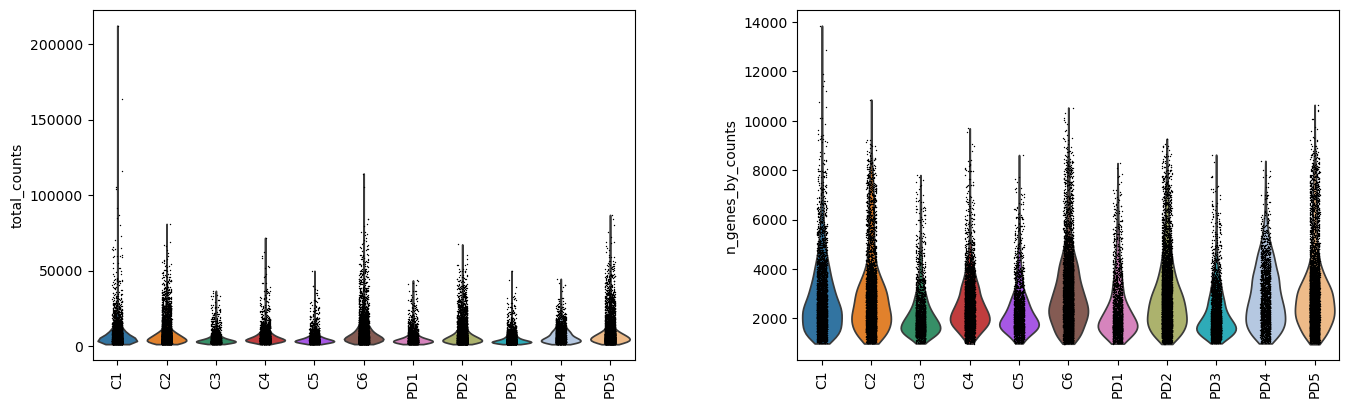

,patient,condition,n_nuclei,median_counts,median_detected_genes
0,C1,Control,3753,5549.0,2499.0
1,C2,Control,4358,5889.5,2643.5
2,C3,Control,2047,3817.0,1911.0
3,C4,Control,4199,5098.0,2323.0
4,C5,Control,2318,3985.5,2052.5
5,C6,Control,5758,6509.0,2744.0
6,PD1,PD,1943,4085.0,2041.0
7,PD2,PD,5925,5584.0,2581.0
8,PD3,PD,3345,3653.0,1939.0
9,PD4,PD,2083,6070.0,2714.0


In [9]:
sc.pp.calculate_qc_metrics(
    adata,
    percent_top=None,
    log1p=False,
    inplace=True
)

sc.pl.violin(
    adata,
    keys=["total_counts", "n_genes_by_counts"],
    groupby="patient",
    rotation=90,
    multi_panel=True
)

qc_summary = (
    adata.obs.groupby(["patient", "condition"], observed=True)
    .agg(
        n_nuclei=("total_counts", "size"),
        median_counts=("total_counts", "median"),
        median_detected_genes=("n_genes_by_counts", "median")
    )
    .reset_index()
)

display(qc_summary)

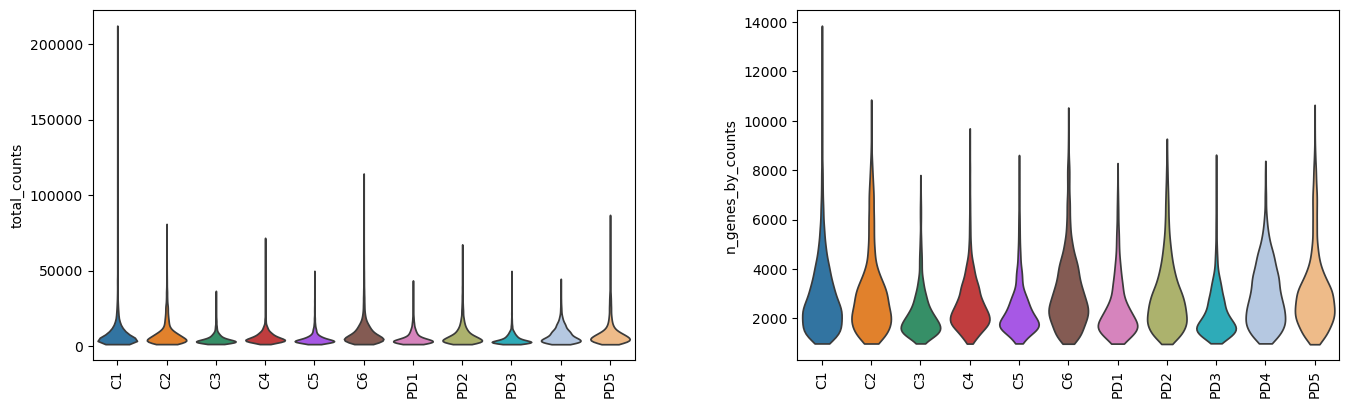

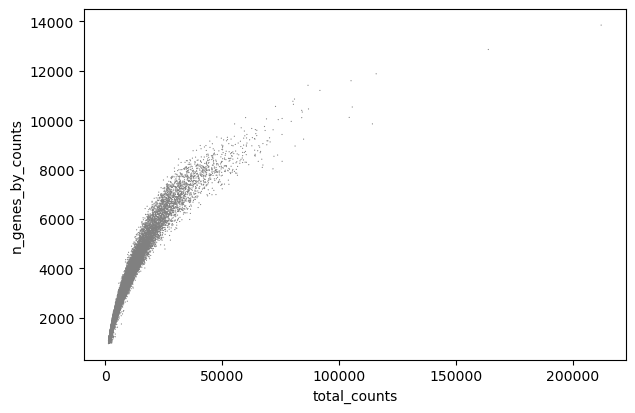

,patient,percentile,total_counts,n_genes_by_counts
0,C1,0.01,1610.04,1066.00
1,C1,0.05,1939.80,1218.60
2,C1,0.50,5549.00,2499.00
3,C1,0.95,21924.60,5735.00
4,C1,0.99,43632.92,8004.04
5,C2,0.01,1592.71,1036.14
6,C2,0.05,1989.00,1216.00
7,C2,0.50,5889.50,2643.50
8,C2,0.95,26639.40,6812.65
9,C2,0.99,43110.20,8127.72


In [11]:
#Inspect QC distributions before filtering

# 1. Compare counts and detected genes across donors
sc.pl.violin(
    adata,
    keys=["total_counts", "n_genes_by_counts"],
    groupby="patient",
    rotation=90,
    multi_panel=True,
    stripplot=False
)

# 2. Inspect the relationship between counts and detected genes
sc.pl.scatter(
    adata,
    x="total_counts",
    y="n_genes_by_counts"
)

# 3. Calculate donor-specific QC percentiles
qc_percentiles = (
    adata.obs.groupby("patient", observed=True)
    [["total_counts", "n_genes_by_counts"]]
    .quantile([0.01, 0.05, 0.50, 0.95, 0.99])
    .rename_axis(index=["patient", "percentile"])
    .reset_index()
)

display(qc_percentiles)

Starting dimensions: (41435, 26737)
After gene filtering: (41435, 26675)
Highly variable genes: 2000


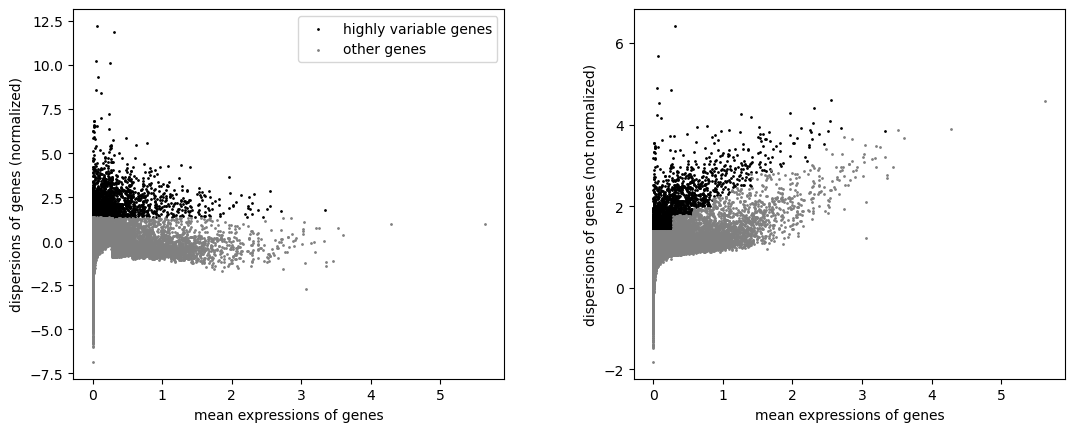

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_2480\3007165364.py:47: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  sc.tl.pca(


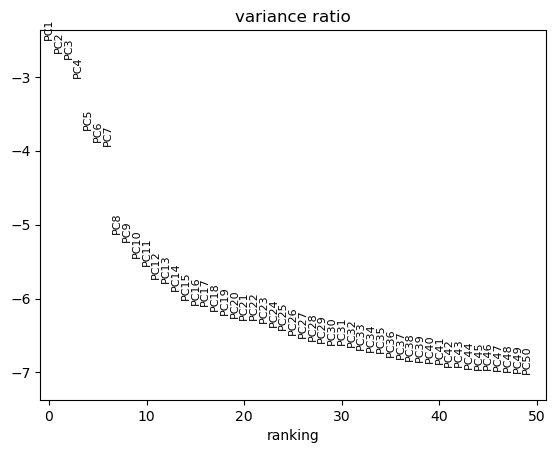

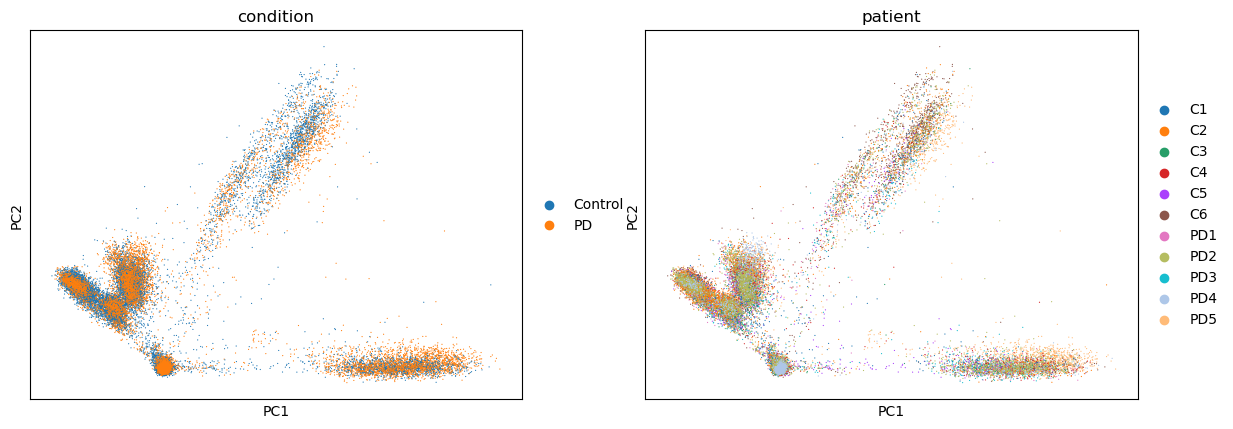


Saved PCA object to: C:\Users\LENOVO\Downloads\GSE157783\GSE157783_PCA.h5ad


In [12]:

# 1. Create a working copy
adata_work = adata.copy()

# Confirm original counts are available
assert "counts" in adata_work.layers, (
    "Original counts layer is missing. Stop before normalization."
)

print("Starting dimensions:", adata_work.shape)

# 2. Remove genes detected in fewer than 3 nuclei
# This filters genes, not nuclei.
sc.pp.filter_genes(adata_work, min_cells=3)

print("After gene filtering:", adata_work.shape)

# 3. Normalize each nucleus to a common library size
sc.pp.normalize_total(adata_work, target_sum=10_000)

# 4. Log-transform normalized expression
sc.pp.log1p(adata_work)

# 5. Identify highly variable genes
sc.pp.highly_variable_genes(
    adata_work,
    n_top_genes=2000,
    flavor="seurat"
)

print(
    "Highly variable genes:",
    int(adata_work.var["highly_variable"].sum())
)

# Visualize the highly variable genes
sc.pl.highly_variable_genes(adata_work)

# 6. Scale the data while retaining sparse representation
# zero_center=False avoids densifying the full sparse matrix.
sc.pp.scale(
    adata_work,
    zero_center=False,
    max_value=10
)

# 7. PCA using highly variable genes
sc.tl.pca(
    adata_work,
    n_comps=50,
    use_highly_variable=True,
    svd_solver="arpack"
)

# 8. Inspect how much variance the principal components explain
sc.pl.pca_variance_ratio(
    adata_work,
    n_pcs=50,
    log=True
)

# 9. Plot the first two principal components
sc.pl.pca(
    adata_work,
    color=["condition", "patient"],
    components=["1,2"]
)

# Save the exploratory object
pca_file = data_dir / "GSE157783_PCA.h5ad"
adata_work.write_h5ad(pca_file, compression="gzip")

print("\nSaved PCA object to:", pca_file)

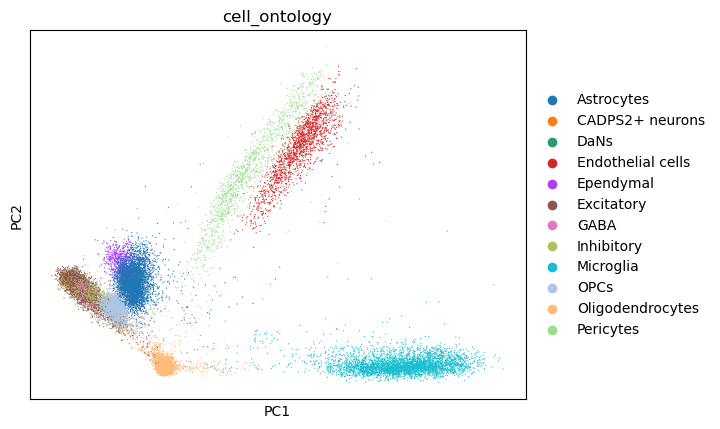

In [17]:
# 1. Inspect PCA colored by the existing cell-type annotations
sc.pl.pca(
    adata_work,
    color=["cell_ontology"],
    components=["1,2"]
)

# 2. Construct a neighborhood graph from the PCA coordinates
sc.pp.neighbors(
    adata_work,
    n_neighbors=15,
    n_pcs=30,
    random_state=42
)


In [18]:

# 3. Generate UMAP coordinates
sc.tl.umap(
    adata_work,
    random_state=42
)

# 4. Identify exploratory clusters
sc.tl.leiden(
    adata_work,
    resolution=0.5,
    key_added="leiden",
    random_state=42,
    flavor="igraph"
)

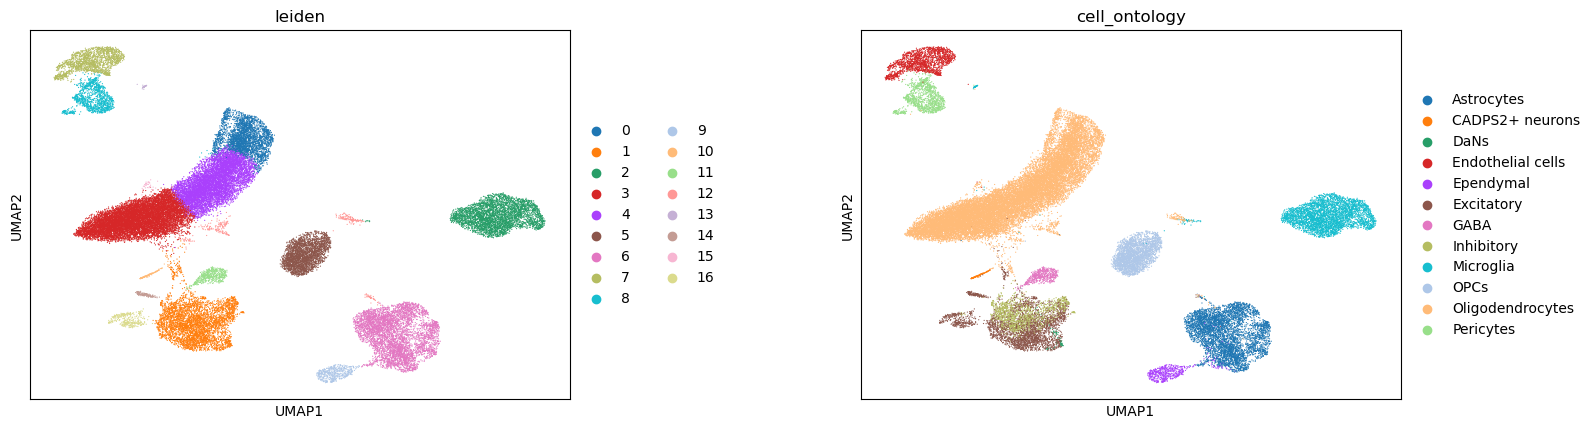

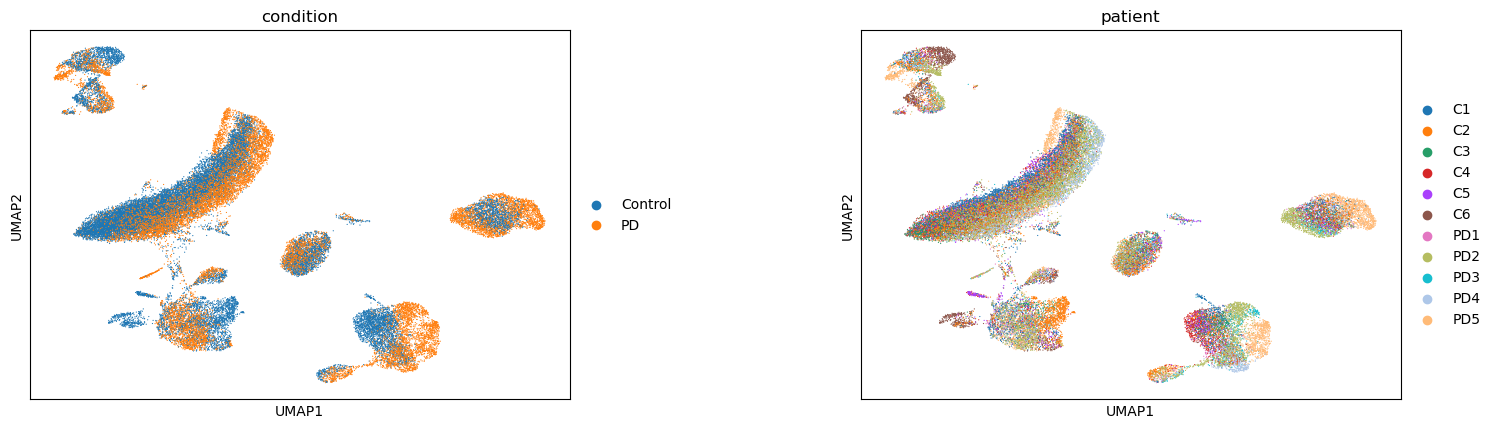

In [19]:
# 5. Compare clusters, known cell types, disease groups, and donors
sc.pl.umap(
    adata_work,
    color=["leiden", "cell_ontology"],
    wspace=0.4
)

sc.pl.umap(
    adata_work,
    color=["condition", "patient"],
    wspace=0.4
)

In [20]:
# 6. Summarize cluster sizes and their known annotations
cluster_summary = pd.crosstab(
    adata_work.obs["leiden"],
    adata_work.obs["cell_ontology"]
)

display(cluster_summary)

# 7. Save the updated exploratory object
adata_work.write_h5ad(
    data_dir / "GSE157783_clustered.h5ad",
    compression="gzip"
)

cell_ontology,Astrocytes,CADPS2+ neurons,DaNs,Endothelial cells,Ependymal,Excitatory,GABA,Inhibitory,Microglia,OPCs,Oligodendrocytes,Pericytes
leiden,,,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0,3044,0
1,0,1,74,0,0,2548,4,1537,0,0,63,0
2,0,0,0,0,0,0,0,0,3820,0,0,0
3,1,0,0,0,0,7,0,0,2,0,10440,0
4,0,0,0,0,0,0,0,0,1,0,7391,0
5,0,0,0,0,0,0,0,0,2,2748,0,0
6,4686,0,0,2,54,0,0,0,2,0,4,0
7,0,0,0,1717,0,0,0,0,1,1,0,16
8,0,0,0,1,0,0,0,0,0,0,10,1212


cell_ontology,Astrocytes,CADPS2+ neurons,DaNs,Endothelial cells,Ependymal,Excitatory,GABA,Inhibitory,Microglia,OPCs,Oligodendrocytes,Pericytes
leiden,,,,,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0
1,0.0,0.0,1.8,0.0,0.0,60.3,0.1,36.4,0.0,0.0,1.5,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.1,0.0,0.0,0.0,0.0,99.9,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1,99.9,0.0,0.0
6,98.7,0.0,0.0,0.0,1.1,0.0,0.0,0.0,0.0,0.0,0.1,0.0
7,0.0,0.0,0.0,99.0,0.0,0.0,0.0,0.0,0.1,0.1,0.0,0.9
8,0.0,0.0,0.0,0.1,0.0,0.0,0.0,0.0,0.0,0.0,0.8,99.1


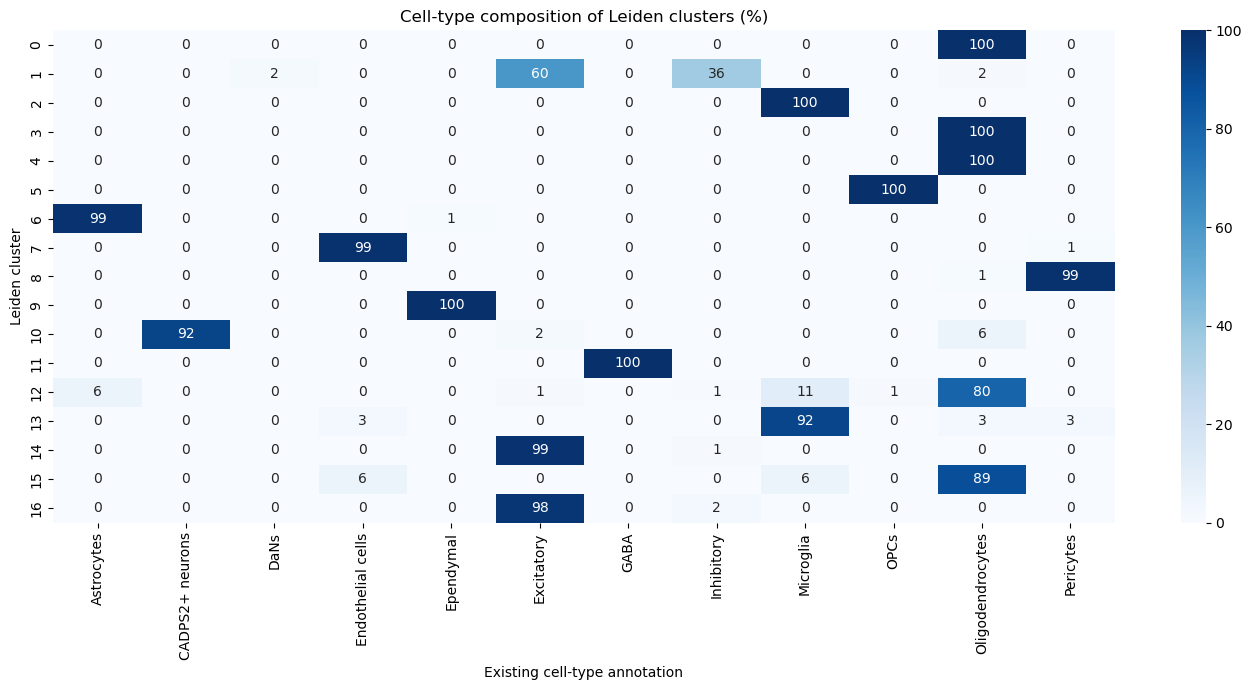

In [22]:
#Calculate the percentage of each cell type within every cluster
# Count nuclei in each cluster and annotated cell type
cluster_counts = pd.crosstab(
    adata_work.obs["leiden"],
    adata_work.obs["cell_ontology"]
)

# Convert counts to percentages within each cluster
cluster_percentages = (
    cluster_counts.div(cluster_counts.sum(axis=1), axis=0) * 100
).round(1)

display(cluster_percentages)

# Plot the distribution as a heatmap
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))
sns.heatmap(
    cluster_percentages,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)
plt.xlabel("Existing cell-type annotation")
plt.ylabel("Leiden cluster")
plt.title("Cell-type composition of Leiden clusters (%)")
plt.tight_layout()
plt.show()

In [23]:
#Check whether clusters are dominated by particular donors
# Donor composition within each cluster
donor_counts = pd.crosstab(
    adata_work.obs["leiden"],
    adata_work.obs["patient"]
)

donor_percentages = (
    donor_counts.div(donor_counts.sum(axis=1), axis=0) * 100
).round(1)

display(donor_percentages)

# Disease composition within each cluster
condition_counts = pd.crosstab(
    adata_work.obs["leiden"],
    adata_work.obs["condition"]
)

condition_percentages = (
    condition_counts.div(condition_counts.sum(axis=1), axis=0) * 100
).round(1)

display(condition_percentages)

patient,C1,C2,C3,C4,C5,C6,PD1,PD2,PD3,PD4,PD5
leiden,,,,,,,,,,,
0,9.4,6.7,2.8,3.6,3.5,13.1,3.4,19.1,7.5,13.4,17.4
1,10.4,22.2,3.7,3.4,4.5,8.2,5.6,15.4,5.8,2.1,18.8
2,4.7,5.3,2.7,8.3,3.0,6.0,5.4,17.0,14.5,3.4,29.6
3,10.4,10.1,8.1,17.7,7.0,14.8,4.7,8.8,6.0,3.9,8.5
4,11.0,10.3,4.0,9.8,7.3,14.5,4.5,16.5,8.9,6.2,7.0
5,9.2,14.0,7.4,8.3,5.6,11.3,3.8,13.7,8.3,4.8,13.5
6,6.3,5.5,5.9,12.1,5.3,10.3,5.4,17.9,9.8,6.5,15.0
7,8.2,11.6,1.8,3.6,2.4,30.8,3.0,13.9,5.9,2.7,16.0
8,7.0,10.5,2.2,4.3,2.1,27.3,5.5,14.7,6.8,3.6,16.0


condition,Control,PD
leiden,,
0,39.1,60.9
1,52.3,47.7
2,30.1,69.9
3,68.1,31.9
4,56.8,43.2
5,55.8,44.2
6,45.4,54.6
7,58.4,41.6
8,53.4,46.6


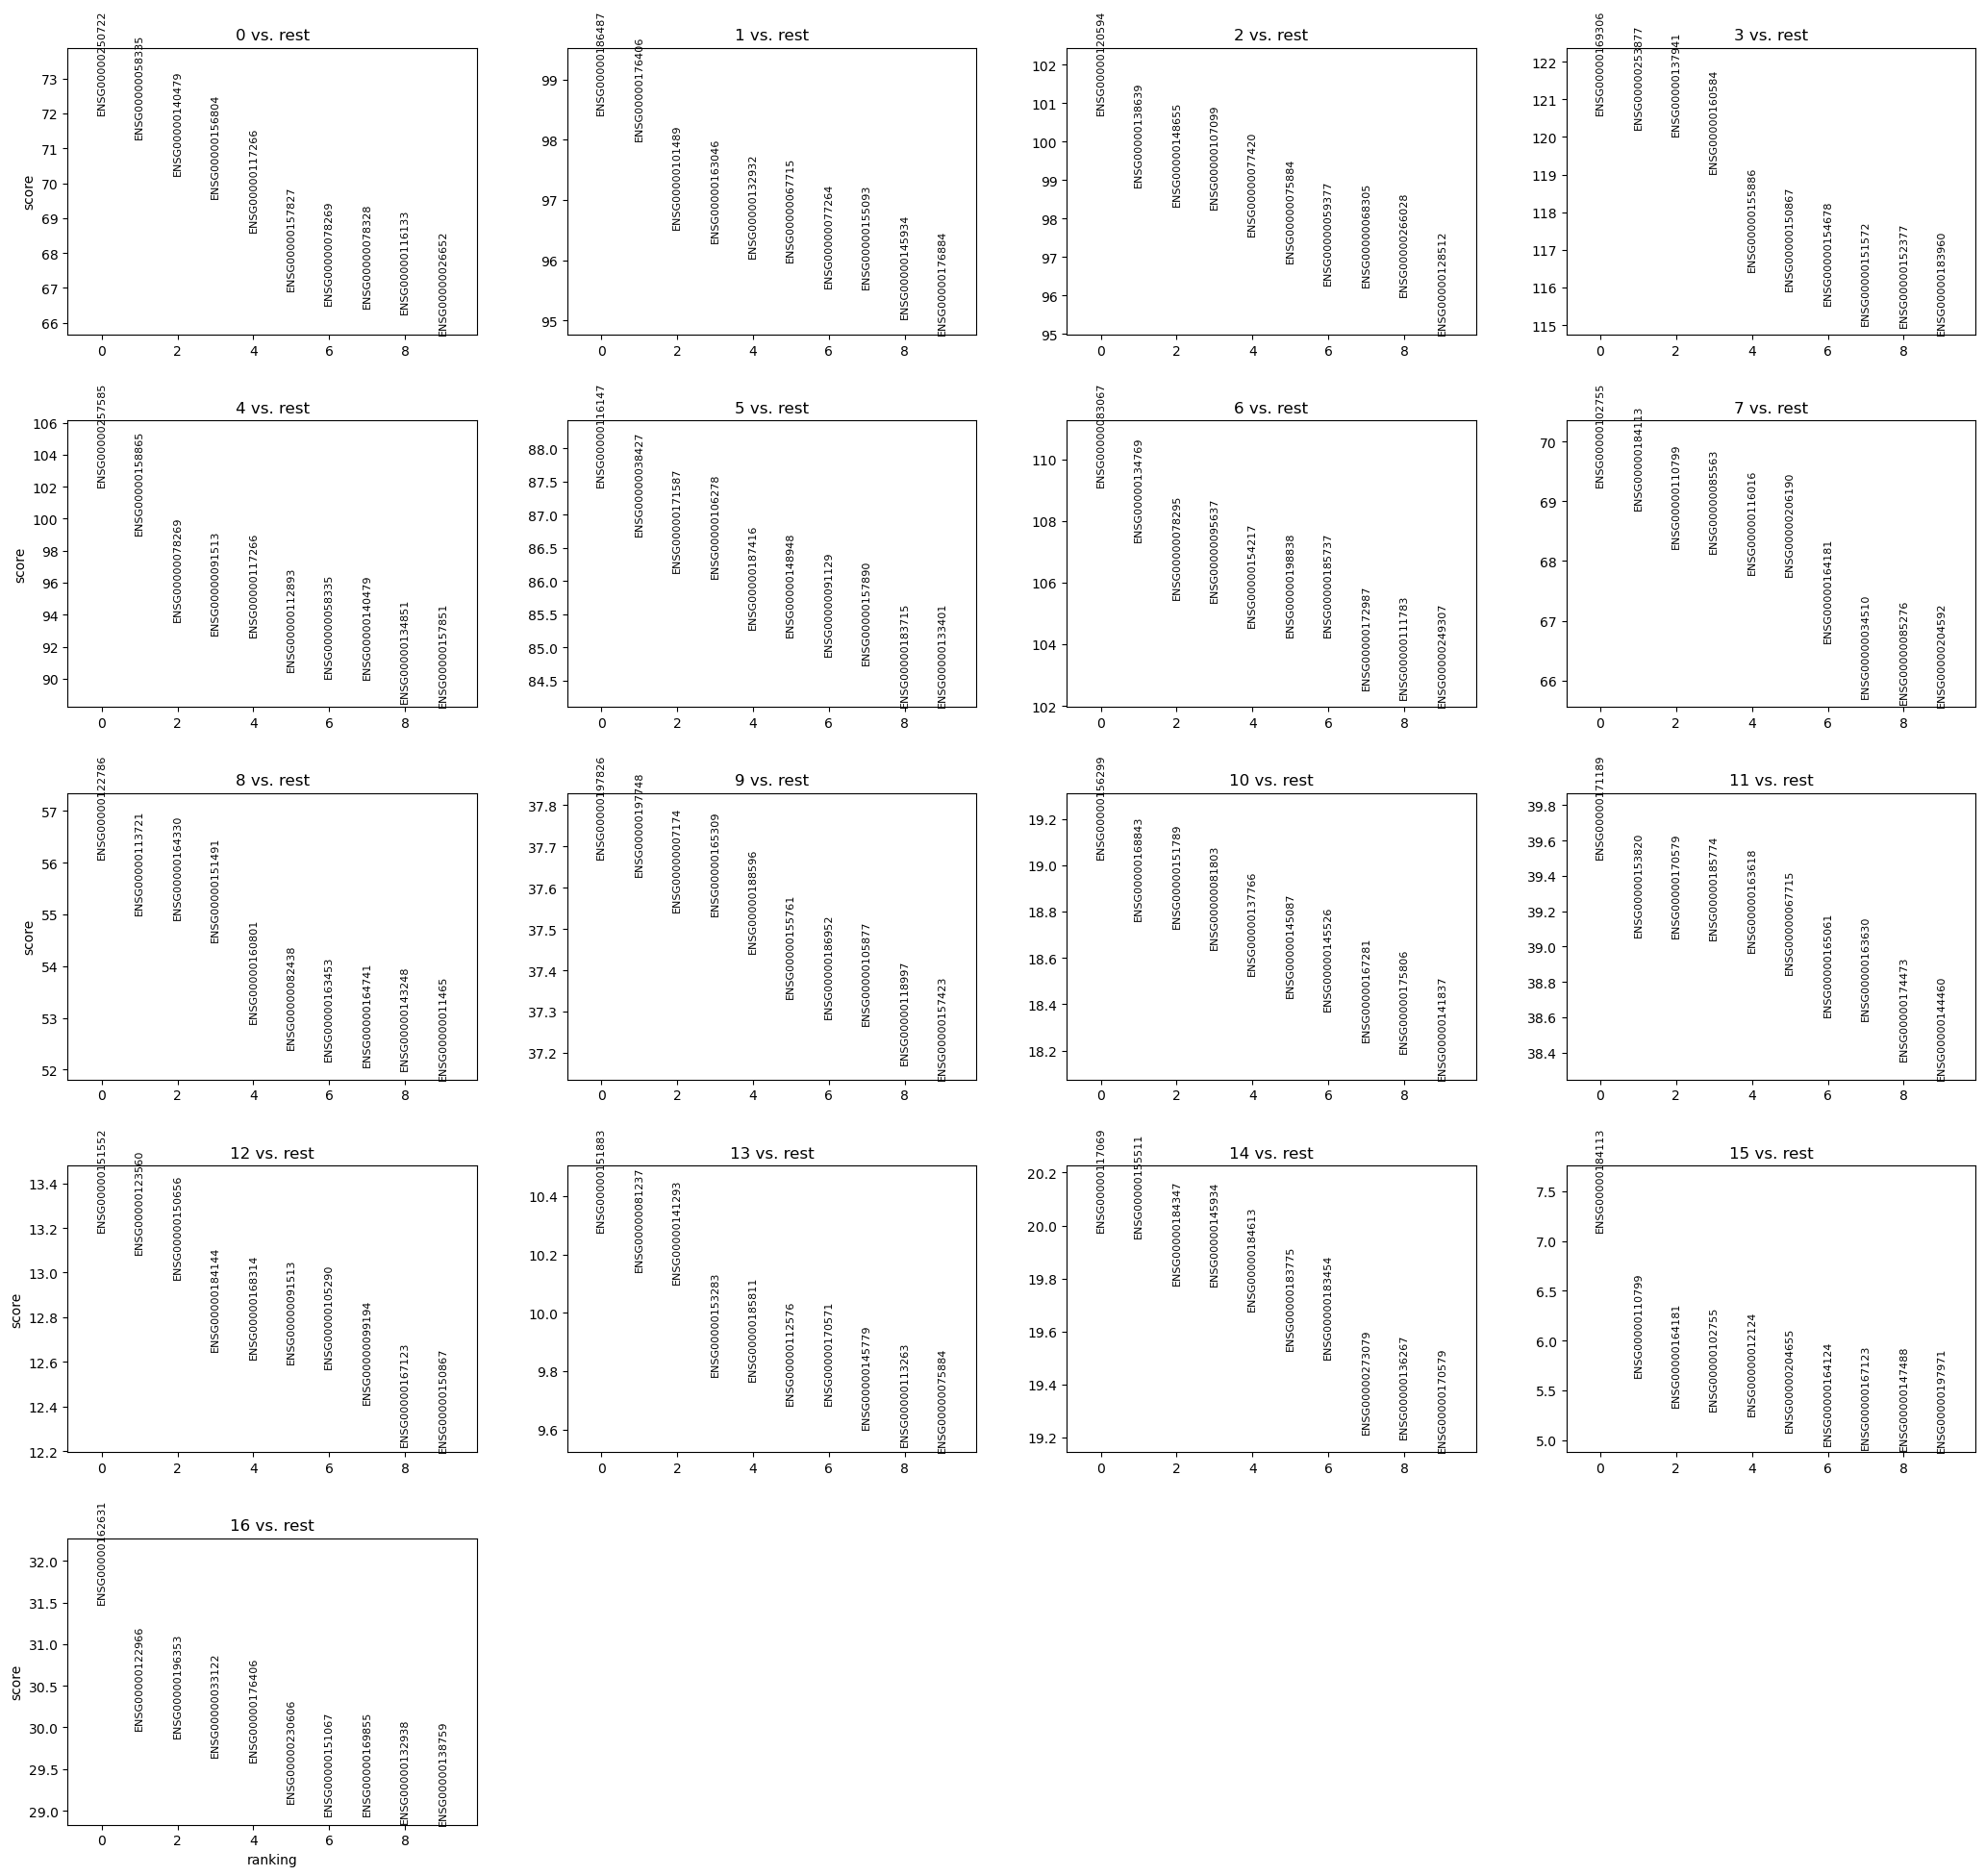

,group,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference
0,0,ENSG00000250722,71.982506,3.093951,0.000000e+00,0.000000e+00,0.977004,0.441562
1,0,ENSG00000058335,71.291794,2.965637,0.000000e+00,0.000000e+00,0.975690,0.352713
2,0,ENSG00000140479,70.244652,3.123922,0.000000e+00,0.000000e+00,0.996058,0.484124
3,0,ENSG00000156804,69.585266,3.095698,0.000000e+00,0.000000e+00,0.947109,0.320570
4,0,ENSG00000117266,68.596542,2.763464,0.000000e+00,0.000000e+00,0.997372,0.520903
...,...,...,...,...,...,...,...,...
240638,9,ENSG00000155761,37.331734,8.713893,5.017496e-305,2.235880e-301,0.987578,0.037190
240639,9,ENSG00000186952,37.284313,5.669796,2.946989e-304,1.125624e-300,0.993789,0.321596
240640,9,ENSG00000105877,37.267830,8.171956,5.450014e-304,1.821463e-300,0.987578,0.042757
240641,9,ENSG00000118997,37.172455,6.524333,1.902081e-302,5.650660e-299,0.991718,0.122949


Saved cluster marker results.


In [25]:
#Find genes that characterize each cluster
# Start from original counts and preserve all available genes
adata_markers = adata.copy()

# Transfer the cluster labels, matching nuclei by barcode
adata_markers.obs["leiden"] = (
    adata_work.obs.loc[adata_markers.obs_names, "leiden"]
    .astype("category")
)

# Normalize and log-transform for marker characterization
sc.pp.normalize_total(adata_markers, target_sum=10_000)
sc.pp.log1p(adata_markers)

# Rank genes that distinguish each cluster from the others
sc.tl.rank_genes_groups(
    adata_markers,
    groupby="leiden",
    method="wilcoxon",
    use_raw=False,
    pts=True
)

# Display the top 10 marker candidates per cluster
sc.pl.rank_genes_groups(
    adata_markers,
    n_genes=10,
    sharey=False
)

# Extract the results into a table
marker_results = sc.get.rank_genes_groups_df(
    adata_markers,
    group=None
)

display(
    marker_results
    .sort_values(["group", "pvals_adj"])
    .groupby("group")
    .head(10)
)

# Save results
marker_results.to_csv(
    data_dir / "GSE157783_cluster_markers.csv",
    index=False
)

print("Saved cluster marker results.")

In [29]:
#Build the pseudobulk count matrix

import anndata as ad
from scipy.sparse import vstack, csr_matrix

counts = adata.layers["counts"]
obs = adata.obs.copy()

obs["patient"] = obs["patient"].astype(str)
obs["cell_ontology"] = obs["cell_ontology"].astype(str)

# Explicitly define the correct donor-to-condition mapping
condition_map = {
    **{f"C{i}": "Control" for i in range(1, 7)},
    **{f"PD{i}": "PD" for i in range(1, 6)}
}

# Check that every donor has a recognized label
unknown_donors = set(obs["patient"].unique()) - set(condition_map)
assert not unknown_donors, f"Unexpected donors: {unknown_donors}"

obs["condition"] = obs["patient"].map(condition_map)

pseudobulk_matrices = []
pseudobulk_metadata = []

for cell_type in sorted(obs["cell_ontology"].unique()):
    type_indices = np.flatnonzero(
        obs["cell_ontology"].to_numpy() == cell_type
    )
    type_obs = obs.iloc[type_indices]

    for patient in sorted(type_obs["patient"].unique()):
        donor_mask = type_obs["patient"].to_numpy() == patient
        donor_indices = type_indices[np.flatnonzero(donor_mask)]

        n_nuclei = len(donor_indices)

        # Sum raw counts across nuclei from this donor and cell type
        summed_counts = np.asarray(
            counts[donor_indices].sum(axis=0)
        ).reshape(1, -1)

        pseudobulk_matrices.append(
            csr_matrix(summed_counts, dtype=np.int64)
        )

        pseudobulk_metadata.append({
            "sample_id": f"{patient}_{cell_type}",
            "patient": patient,
            "condition": condition_map[patient],
            "cell_ontology": cell_type,
            "n_nuclei": n_nuclei
        })

pb_matrix = vstack(pseudobulk_matrices, format="csr")

pb_obs = pd.DataFrame(pseudobulk_metadata)
pb_obs.index = pb_obs["sample_id"].astype(str)

adata_pb = ad.AnnData(
    X=pb_matrix,
    obs=pb_obs,
    var=adata.var.copy()
)

adata_pb.layers["counts"] = adata_pb.X.copy()

# Verify that donor conditions are assigned correctly
print("Donor-to-condition mapping:")
print(
    adata_pb.obs[["patient", "condition"]]
    .drop_duplicates()
    .sort_values("patient")
    .to_string(index=False)
)

print("\nNumber of pseudobulk samples by condition:")
print(
    adata_pb.obs.groupby("condition", observed=True)["patient"]
    .nunique()
)

# Save corrected dataset
adata_pb.write_h5ad(
    data_dir / "GSE157783_pseudobulk.h5ad",
    compression="gzip"
)


Donor-to-condition mapping:
patient condition
     C1   Control
     C2   Control
     C3   Control
     C4   Control
     C5   Control
     C6   Control
    PD1        PD
    PD2        PD
    PD3        PD
    PD4        PD
    PD5        PD

Number of pseudobulk samples by condition:
condition
Control    6
PD         5
Name: patient, dtype: int64


In [30]:
#Check whether each donor has enough nuclei per cell type
# Donor-level cell numbers for each cell type
cell_number_table = adata_pb.obs.pivot(
    index="cell_ontology",
    columns="patient",
    values="n_nuclei"
).fillna(0).astype(int)

display(cell_number_table)

availability_rows = []

for cell_type, group in adata_pb.obs.groupby(
    "cell_ontology", observed=True
):
    usable = group[group["n_nuclei"] >= 20]

    availability_rows.append({
        "cell_type": cell_type,
        "control_donors_ge20_nuclei": int(
            (usable["condition"] == "Control").sum()
        ),
        "PD_donors_ge20_nuclei": int(
            (usable["condition"] == "PD").sum()
        ),
        "total_donors_ge20_nuclei": len(usable)
    })

availability = pd.DataFrame(availability_rows)
display(availability)


patient,C1,C2,C3,C4,C5,C6,PD1,PD2,PD3,PD4,PD5
cell_ontology,,,,,,,,,,,
Astrocytes,316,259,274,563,246,485,256,847,466,285,711
CADPS2+ neurons,0,0,1,0,2,0,11,23,37,0,46
DaNs,22,0,0,2,5,3,1,15,0,0,26
Endothelial cells,142,200,30,64,40,529,52,242,103,47,274
Ependymal,12,134,6,38,10,11,38,108,70,26,83
Excitatory,248,613,91,146,197,526,173,416,159,54,414
GABA,44,33,4,30,18,157,33,73,10,40,93
Inhibitory,163,347,67,56,68,98,59,208,88,36,358
Microglia,192,206,109,321,140,237,207,653,556,129,1153


,cell_type,control_donors_ge20_nuclei,PD_donors_ge20_nuclei,total_donors_ge20_nuclei
0,Astrocytes,6,5,11
1,CADPS2+ neurons,0,3,3
2,DaNs,1,1,2
3,Endothelial cells,6,5,11
4,Ependymal,2,5,7
5,Excitatory,6,5,11
6,GABA,4,4,8
7,Inhibitory,6,5,11
8,Microglia,6,5,11
9,OPCs,6,5,11


Uses only the eight primary cell types selected above.
Excludes donor–cell-type samples with fewer than 20 nuclei or fewer than 1,000 total counts.
Requires at least three donors in each condition.
Compares PD against Control.
Saves a separate results CSV for each cell type.

In [32]:
#Run PD versus Control differential expression

from pathlib import Path
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

output_dir = data_dir / "pseudobulk_DE_results"
output_dir.mkdir(parents=True, exist_ok=True)

primary_cell_types = [
    "Astrocytes",
    "Endothelial cells",
    "Excitatory",
    "Inhibitory",
    "Microglia",
    "OPCs",
    "Oligodendrocytes",
    "Pericytes",
]

all_results = []

for cell_type in primary_cell_types:
    print(f"\nAnalyzing: {cell_type}")

    # Select this cell type's donor-level pseudobulk samples
    meta = adata_pb.obs[
        adata_pb.obs["cell_ontology"] == cell_type
    ].copy()

    # Apply preliminary pseudobulk quality filters
    sample_counts = np.asarray(
        adata_pb[meta.index].layers["counts"].sum(axis=1)
    ).ravel()

    meta["total_counts"] = sample_counts

    meta = meta[
        (meta["n_nuclei"] >= 20) &
        (meta["total_counts"] >= 1000)
    ].copy()

    # Confirm sufficient biological replication
    donor_counts = meta.groupby(
        "condition", observed=True
    )["patient"].nunique()

    n_control = int(donor_counts.get("Control", 0))
    n_pd = int(donor_counts.get("PD", 0))

    print(f"Control donors: {n_control}; PD donors: {n_pd}")

    if n_control < 3 or n_pd < 3:
        print("Skipped: fewer than 3 donors in a condition.")
        continue

    # Raw integer counts: samples x genes
    count_array = adata_pb[meta.index].layers["counts"]
    if hasattr(count_array, "toarray"):
        count_array = count_array.toarray()

    counts_df = pd.DataFrame(
        count_array,
        index=meta.index,
        columns=adata_pb.var_names
    ).astype("int64")

    # Remove genes with very low counts across samples
    keep_genes = (counts_df >= 10).sum(axis=0) >= 3
    counts_df = counts_df.loc[:, keep_genes]

    # Metadata rows must match count matrix rows exactly
    metadata = meta[["condition"]].copy()
    metadata["condition"] = pd.Categorical(
        metadata["condition"],
        categories=["Control", "PD"]
    )
    metadata = metadata.loc[counts_df.index]

    # Differential expression: PD relative to Control
    dds = DeseqDataSet(
        counts=counts_df,
        metadata=metadata,
        design="~condition",
        refit_cooks=True,
        n_cpus=4
    )
    dds.deseq2()

    stats = DeseqStats(
        dds,
        contrast=("condition", "PD", "Control"),
        n_cpus=4
    )
    stats.summary()

    result = stats.results_df.copy()
    result.index.name = "gene_id"
    result = result.reset_index()
    result["cell_type"] = cell_type

    result = result.sort_values("padj", na_position="last")

    result.to_csv(
        output_dir / f"{cell_type.replace(' ', '_')}_PD_vs_Control.csv",
        index=False
    )

    all_results.append(result)

    significant = result[
        (result["padj"] < 0.05) &
        (result["log2FoldChange"].abs() >= 1)
    ]

    print(f"Genes tested: {len(result)}")
    print(f"Significant genes (FDR < 0.05, |log2FC| >= 1): {len(significant)}")
    display(significant.head(10))

# Combine all cell-type results into one file
if all_results:
    combined_results = pd.concat(all_results, ignore_index=True)
    combined_results.to_csv(
        output_dir / "ALL_cell_types_PD_vs_Control.csv",
        index=False
    )
    print(f"\nResults saved in: {output_dir}")
else:
    print("No cell types passed the filtering and replication checks.")



Analyzing: Astrocytes
Control donors: 6; PD donors: 5
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 15.45 seconds.

Fitting dispersion trend curve...
... done in 1.14 seconds.

Fitting MAP dispersions...
... done in 15.27 seconds.

Fitting LFCs...
... done in 8.13 seconds.

Calculating cook's distance...
... done in 0.03 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 2.71 seconds.



Log2 fold change & Wald test p-value: condition PD vs Control
                  baseMean  log2FoldChange     lfcSE      stat    pvalue  \
gene                                                                       
ENSG00000238009   7.647655        0.038190  0.513487  0.074374  0.940713   
ENSG00000237491  53.258554       -0.101483  0.246936 -0.410968  0.681096   
ENSG00000223764   8.518629        0.143553  0.715998  0.200494  0.841094   
ENSG00000187634  37.559533        1.008088  0.593199  1.699410  0.089242   
ENSG00000188976  24.545146        0.539177  0.311714  1.729717  0.083681   
...                    ...             ...       ...       ...       ...   
ENSG00000233221   5.987856        0.383736  0.807747  0.475070  0.634737   
ENSG00000249008   6.523688       -1.836061  0.823588 -2.229343  0.025791   
ENSG00000225083   5.288767        0.231053  0.882159  0.261918  0.793385   
ENSG00000258548  20.034904       -0.819484  0.607326 -1.349331  0.177231   
ENSG00000275910   2.645727

,gene_id,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,cell_type
6991,ENSG00000196739,470.879381,1.492671,0.235480,6.338835,2.315089e-10,0.000003,Astrocytes
10734,ENSG00000149922,24.954444,2.157314,0.359371,6.003023,1.936767e-09,0.000013,Astrocytes
8086,ENSG00000150051,47.314593,1.641819,0.280943,5.843953,5.097638e-09,0.000022,Astrocytes
3638,ENSG00000251165,46.209394,-2.631908,0.453710,-5.800864,6.597397e-09,0.000022,Astrocytes
2696,ENSG00000144810,95.637376,1.850506,0.335287,5.519163,3.406182e-08,0.000092,Astrocytes
11973,ENSG00000267586,112.167352,1.891169,0.350914,5.389264,7.074688e-08,0.000120,Astrocytes
8954,ENSG00000257815,173.992576,-1.405220,0.259808,-5.408677,6.349216e-08,0.000120,Astrocytes
8560,ENSG00000130035,70.285356,1.555718,0.287339,5.414220,6.155648e-08,0.000120,Astrocytes
3905,ENSG00000164199,214.462768,-3.434442,0.640401,-5.362958,8.186992e-08,0.000123,Astrocytes
590,ENSG00000171502,45.627301,2.083210,0.395536,5.266808,1.388160e-07,0.000171,Astrocytes



Analyzing: Endothelial cells
Control donors: 6; PD donors: 5
Using None as control genes, passed at DeseqDataSet initialization


...


Analyzing: Pericytes
Control donors: 6; PD donors: 5
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 6.86 seconds.

Fitting dispersion trend curve...
... done in 0.61 seconds.

Fitting MAP dispersions...
... done in 7.40 seconds.

Fitting LFCs...
... done in 5.16 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 2.02 seconds.



Log2 fold change & Wald test p-value: condition PD vs Control
                   baseMean  log2FoldChange     lfcSE      stat    pvalue  \
gene                                                                        
ENSG00000237491    8.352918       -0.141813  0.453237 -0.312889  0.754365   
ENSG00000188976   11.105138       -0.183893  0.468761 -0.392295  0.694840   
ENSG00000272512   35.865043       -0.648598  0.750947 -0.863707  0.387749   
ENSG00000188290  258.709267       -0.163432  0.261669 -0.624576  0.532250   
ENSG00000187608   49.101516       -0.586286  0.290603 -2.017479  0.043646   
...                     ...             ...       ...       ...       ...   
ENSG00000160310   46.137979        0.043493  0.259240  0.167770  0.866764   
ENSG00000273748   21.189289        1.194845  0.394547  3.028398  0.002459   
ENSG00000278817    5.958172       -0.117931  0.618696 -0.190612  0.848830   
ENSG00000256694    4.582957        0.385148  0.813113  0.473671  0.635734   
ENSG0000025654

,gene_id,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,cell_type
4398,ENSG00000123560,52.808832,-1.759891,0.369290,-4.765609,0.000002,0.012361,Pericytes
1457,ENSG00000091409,76.775439,-1.072206,0.228064,-4.701344,0.000003,0.012361,Pericytes
3303,ENSG00000204389,89.527550,2.344103,0.514514,4.555956,0.000005,0.016626,Pericytes
2764,ENSG00000164188,35.344911,1.940837,0.438981,4.421230,0.000010,0.019435,Pericytes
1961,ENSG00000185008,29.103823,1.782016,0.403741,4.413756,0.000010,0.019435,Pericytes
3718,ENSG00000146555,35.658540,1.389566,0.325550,4.268361,0.000020,0.031391,Pericytes
1804,ENSG00000168314,13.892781,-2.563861,0.609320,-4.207742,0.000026,0.035245,Pericytes
4049,ENSG00000164604,30.277701,-1.633891,0.398257,-4.102607,0.000041,0.039075,Pericytes
2551,ENSG00000188517,5.635925,-2.956684,0.730019,-4.050146,0.000051,0.044508,Pericytes
677,ENSG00000125462,10.176361,-2.654708,0.674990,-3.932961,0.000084,0.044587,Pericytes



Results saved in: C:\Users\LENOVO\Downloads\GSE157783\pseudobulk_DE_results


How to interpret the results
- log2FoldChange > 0: higher expression in PD.
- log2FoldChange < 0: lower expression in PD.
- padj < 0.05: statistically significant after multiple-testing correction.
- |log2FoldChange| >= 1: at least a twofold difference in either direction.

SUMMARY: SIGNIFICANT GENES BY BRAIN CELL TYPE
Criteria: adjusted p-value < 0.05 and |log2FC| >= 1


,rank,cell_type,significant_genes
0,1,Microglia,385
1,2,Oligodendrocytes,282
2,3,Astrocytes,211
3,4,Excitatory,156
4,5,Inhibitory,41
5,6,Pericytes,16
6,7,OPCs,13
7,8,Endothelial cells,11


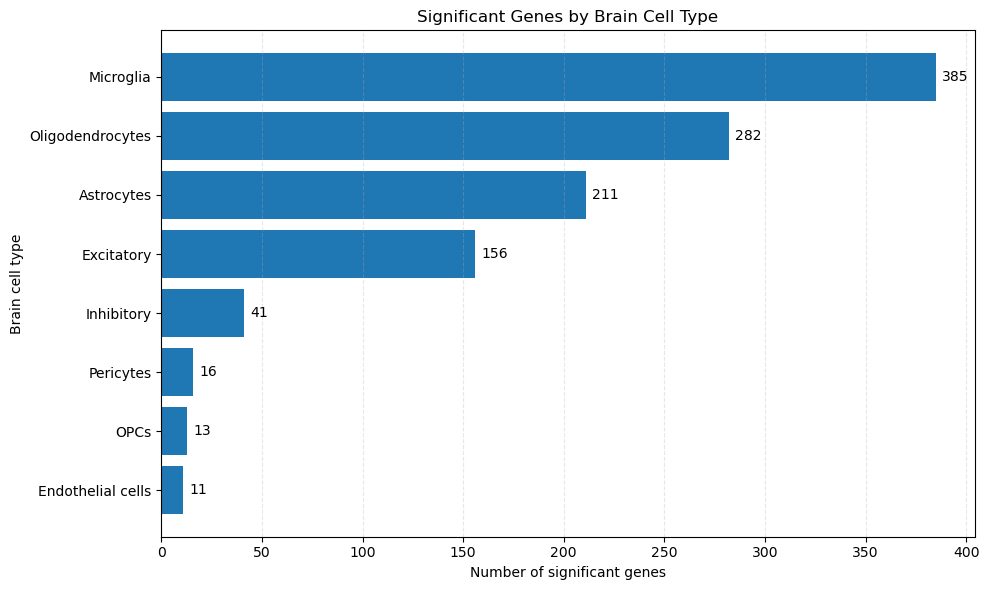

Summary and graph saved to: C:\Users\LENOVO\Downloads\GSE157783\pseudobulk_DE_results


In [34]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Define the significance criteria
FDR_CUTOFF = 0.05
LOG2FC_CUTOFF = 1

# 2. Filter significant genes
significant = combined_results[
    (combined_results["padj"] < FDR_CUTOFF) &
    (combined_results["log2FoldChange"].abs() >= LOG2FC_CUTOFF)
].copy()

# 3. Create the summary table
summary = (
    significant.groupby("cell_type")["gene_id"]
    .nunique()
    .reset_index(name="significant_genes")
)

# Include cell types with zero significant genes, if any
all_cell_types = sorted(combined_results["cell_type"].dropna().unique())

summary = (
    summary.set_index("cell_type")
    .reindex(all_cell_types, fill_value=0)
    .reset_index()
)

summary = summary.sort_values(
    "significant_genes", ascending=False
).reset_index(drop=True)

# Add rank
summary.insert(0, "rank", range(1, len(summary) + 1))

print("SUMMARY: SIGNIFICANT GENES BY BRAIN CELL TYPE")
print("Criteria: adjusted p-value < 0.05 and |log2FC| >= 1")
display(summary)

# Save the summary table
summary.to_csv(
    output_dir / "significant_genes_summary_by_cell_type.csv",
    index=False
)

# 4. Plot the bar graph
plot_data = summary.sort_values(
    "significant_genes", ascending=True
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    plot_data["cell_type"],
    plot_data["significant_genes"]
)

plt.xlabel("Number of significant genes")
plt.ylabel("Brain cell type")
plt.title("Significant Genes by Brain Cell Type")
plt.grid(axis="x", linestyle="--", alpha=0.3)

# Display count at the end of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 3,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)}",
        va="center"
    )

plt.tight_layout()

# Save the graph at publication-friendly resolution
plt.savefig(
    output_dir / "significant_genes_by_brain_cell_type.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Summary and graph saved to:", output_dir)


In [35]:
#Before interpreting the genes, check their reliability

# Use the combined results already generated by your analysis
required_columns = {
    "gene_id", "cell_type", "log2FoldChange", "pvalue", "padj"
}
assert required_columns.issubset(combined_results.columns)

results = combined_results.copy()

# Remove Ensembl version suffixes if present
results["gene_id"] = (
    results["gene_id"].astype(str).str.replace(r"\.\d+$", "", regex=True)
)

results["padj"] = pd.to_numeric(results["padj"], errors="coerce")
results["log2FoldChange"] = pd.to_numeric(
    results["log2FoldChange"], errors="coerce"
)

significant = results[
    (results["padj"] < 0.05) &
    (results["log2FoldChange"].abs() >= 1)
].copy()

significant["direction"] = np.where(
    significant["log2FoldChange"] > 0,
    "Higher in PD",
    "Lower in PD"
)

# Save all significant gene-cell-type associations
significant.to_csv(
    output_dir / "significant_brain_genes_by_cell_type.csv",
    index=False
)

# Summarize results and direction
summary = (
    significant.groupby(["cell_type", "direction"])
    .size()
    .unstack(fill_value=0)
)

display(summary)

# Identify genes significant in multiple cell types
gene_recurrence = (
    significant.groupby("gene_id")
    .agg(
        number_of_cell_types=("cell_type", "nunique"),
        cell_types=("cell_type", lambda x: "; ".join(sorted(set(x)))),
        directions=("direction", lambda x: "; ".join(sorted(set(x))))
    )
    .sort_values("number_of_cell_types", ascending=False)
)

display(gene_recurrence.head(30))

gene_recurrence.to_csv(
    output_dir / "recurrent_brain_candidate_genes.csv"
)

print("Significant gene-cell-type associations:", len(significant))
print("Unique significant Ensembl IDs:", significant["gene_id"].nunique())
print("Files saved to:", output_dir)


direction,Higher in PD,Lower in PD
cell_type,,
Astrocytes,136,75
Endothelial cells,6,5
Excitatory,50,106
Inhibitory,16,25
Microglia,36,349
OPCs,10,3
Oligodendrocytes,168,114
Pericytes,5,11


,number_of_cell_types,cell_types,directions
gene_id,,,
ENSG00000207955,4,Astrocytes; Excitatory; Microglia; Oligodendro...,Lower in PD
ENSG00000110172,4,Astrocytes; Microglia; OPCs; Oligodendrocytes,Higher in PD
ENSG00000099622,4,Astrocytes; Inhibitory; Microglia; Oligodendro...,Lower in PD
ENSG00000187134,3,Astrocytes; OPCs; Pericytes,Higher in PD
ENSG00000120694,3,Endothelial cells; Microglia; Oligodendrocytes,Higher in PD
ENSG00000176046,3,Astrocytes; Microglia; Oligodendrocytes,Higher in PD
ENSG00000253661,3,Astrocytes; Excitatory; Oligodendrocytes,Higher in PD; Lower in PD
ENSG00000243927,3,Astrocytes; Microglia; Oligodendrocytes,Higher in PD
ENSG00000260392,3,Excitatory; Inhibitory; Oligodendrocytes,Higher in PD


Significant gene-cell-type associations: 1115
Unique significant Ensembl IDs: 1009
Files saved to: C:\Users\LENOVO\Downloads\GSE157783\pseudobulk_DE_results


In [37]:

import mygene

mg = mygene.MyGeneInfo()

# Retrieve unique human Ensembl gene IDs from significant results
gene_ids = significant["gene_id"].dropna().astype(str).unique().tolist()

mapping = mg.querymany(
    gene_ids,
    scopes="ensembl.gene",
    fields="symbol,name",
    species="human",
    as_dataframe=False,
    verbose=False
)

mapping_df = pd.DataFrame(mapping)

# Keep successfully mapped genes
mapping_df = mapping_df[
    mapping_df["notfound"].isna()
    if "notfound" in mapping_df.columns
    else mapping_df.index == mapping_df.index
].copy()

mapping_df = mapping_df.rename(columns={"query": "gene_id"})

mapping_df = mapping_df[
    ["gene_id", "symbol", "name"]
].drop_duplicates("gene_id")

# Add symbols to significant gene-cell-type associations
significant_named = significant.merge(
    mapping_df,
    on="gene_id",
    how="left"
)

significant_named.to_csv(
    output_dir / "significant_brain_genes_with_symbols.csv",
    index=False
)

# Add symbols to the recurrent-gene table
recurrent_named = (
    gene_recurrence.reset_index()
    .merge(mapping_df, on="gene_id", how="left")
    .sort_values("number_of_cell_types", ascending=False)
)

display(recurrent_named.head(30))

recurrent_named.to_csv(
    output_dir / "recurrent_brain_candidates_with_symbols.csv",
    index=False
)

print("Unique Ensembl IDs:", len(gene_ids))
print("IDs mapped to symbols:", mapping_df["symbol"].notna().sum())


,gene_id,number_of_cell_types,cell_types,directions,symbol,name
0,ENSG00000207955,4,Astrocytes; Excitatory; Microglia; Oligodendro...,Lower in PD,MIR219A2HG,MIR219A2 host gene
2,ENSG00000099622,4,Astrocytes; Inhibitory; Microglia; Oligodendro...,Lower in PD,CIRBP,cold inducible RNA binding protein
1,ENSG00000110172,4,Astrocytes; Microglia; OPCs; Oligodendrocytes,Higher in PD,CHORDC1,cysteine and histidine rich domain containing 1
6,ENSG00000253661,3,Astrocytes; Excitatory; Oligodendrocytes,Higher in PD; Lower in PD,LOC107986952,uncharacterized LOC107986952
8,ENSG00000260392,3,Excitatory; Inhibitory; Oligodendrocytes,Higher in PD,NaN,NaN
7,ENSG00000243927,3,Astrocytes; Microglia; Oligodendrocytes,Higher in PD,MRPS6,mitochondrial ribosomal protein S6
9,ENSG00000174226,3,Excitatory; Inhibitory; Oligodendrocytes,Higher in PD,SNX31,sorting nexin 31
5,ENSG00000176046,3,Astrocytes; Microglia; Oligodendrocytes,Higher in PD,NUPR1,"nuclear protein 1, transcriptional regulator"
4,ENSG00000120694,3,Endothelial cells; Microglia; Oligodendrocytes,Higher in PD,HSPH1,heat shock protein family H (Hsp110) member 1
3,ENSG00000187134,3,Astrocytes; OPCs; Pericytes,Higher in PD,AKR1C1,aldo-keto reductase family 1 member C1


Unique Ensembl IDs: 1009
IDs mapped to symbols: 931


In [38]:

candidate_symbols = [
    "MIR219A2HG",
    "CIRBP",
    "CHORDC1",
    "MRPS6",
    "SNX31",
    "NUPR1",
    "HSPH1",
    "AKR1C1",
]

candidate_results = significant_named[
    significant_named["symbol"].isin(candidate_symbols)
].copy()

candidate_results["direction"] = np.where(
    candidate_results["log2FoldChange"] > 0,
    "Higher in PD",
    "Lower in PD"
)

columns_to_show = [
    "symbol",
    "gene_id",
    "cell_type",
    "log2FoldChange",
    "padj",
    "baseMean",
    "direction",
]

candidate_results = candidate_results.sort_values(
    ["symbol", "cell_type"]
)

display(candidate_results[columns_to_show])

candidate_results[columns_to_show].to_csv(
    output_dir / "priority_candidate_gene_details.csv",
    index=False
)


,symbol,gene_id,cell_type,log2FoldChange,padj,baseMean,direction
68,AKR1C1,ENSG00000187134,Astrocytes,2.365891,0.005130,30.003992,Higher in PD
809,AKR1C1,ENSG00000187134,OPCs,2.593530,0.019646,7.483245,Higher in PD
1112,AKR1C1,ENSG00000187134,Pericytes,2.487316,0.044587,16.943472,Higher in PD
133,CHORDC1,ENSG00000110172,Astrocytes,1.377851,0.024817,61.794010,Higher in PD
570,CHORDC1,ENSG00000110172,Microglia,1.286720,0.009380,69.459443,Higher in PD
812,CHORDC1,ENSG00000110172,OPCs,1.175321,0.034718,60.714571,Higher in PD
896,CHORDC1,ENSG00000110172,Oligodendrocytes,1.410794,0.004137,875.732278,Higher in PD
198,CIRBP,ENSG00000099622,Astrocytes,-1.101837,0.045923,327.813627,Lower in PD
407,CIRBP,ENSG00000099622,Inhibitory,-1.029355,0.042423,150.398601,Lower in PD
669,CIRBP,ENSG00000099622,Microglia,-1.188196,0.020950,113.081351,Lower in PD


Prioritize these eight candidates
Gene	Cell types with significant results	Direction in the listed cell types
MIR219A2HG	4	Lower in PD
CIRBP	4	Lower in PD
CHORDC1	4	Higher in PD
AKR1C1	3	Higher in PD
HSPH1	3	Higher in PD
MRPS6	3	Higher in PD
NUPR1	3	Higher in PD
SNX31	3	Higher in PD

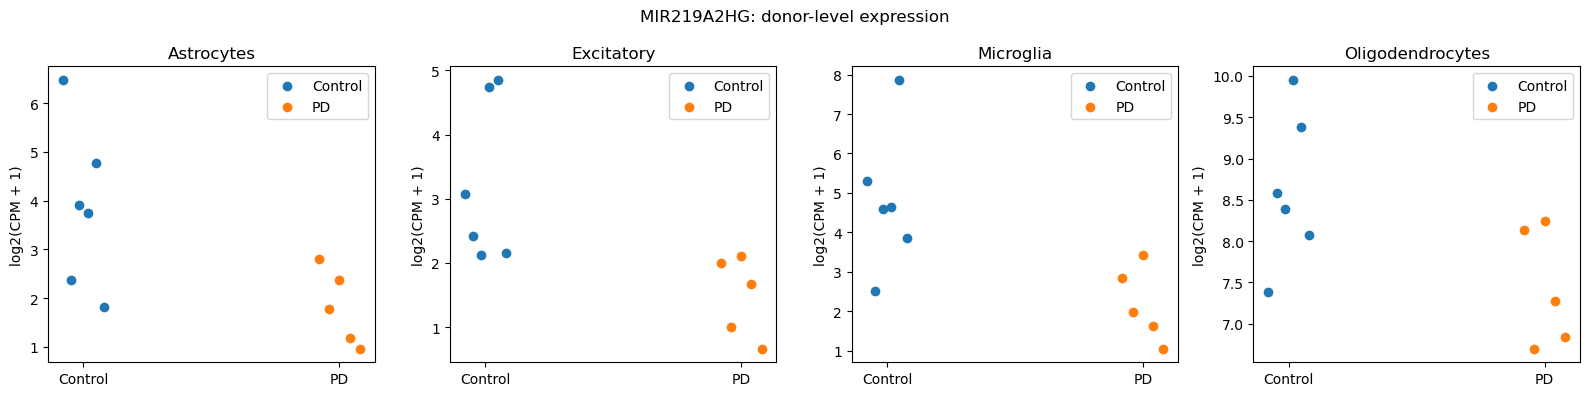

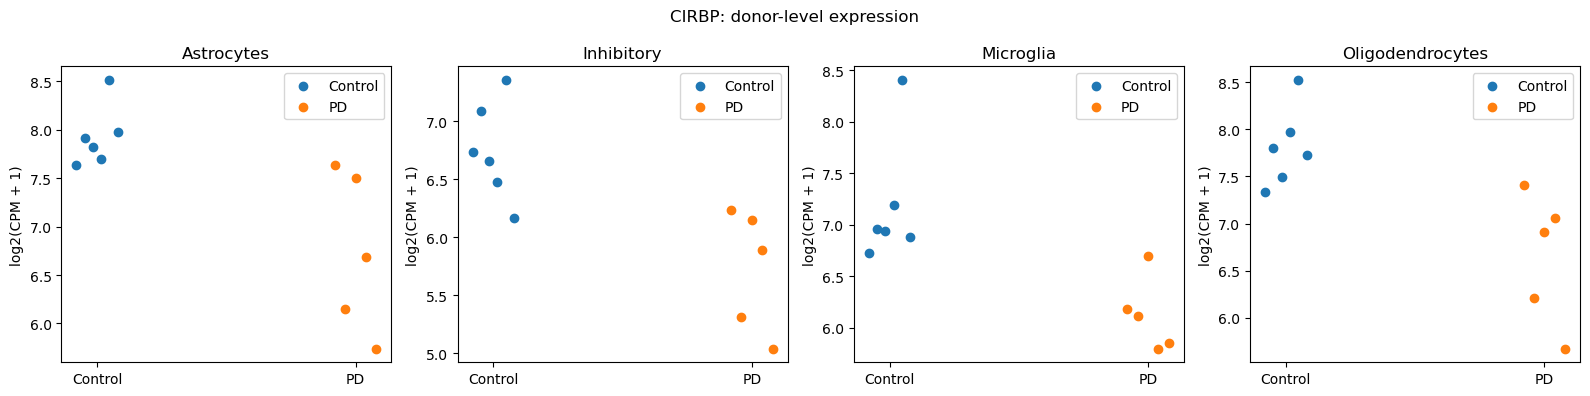

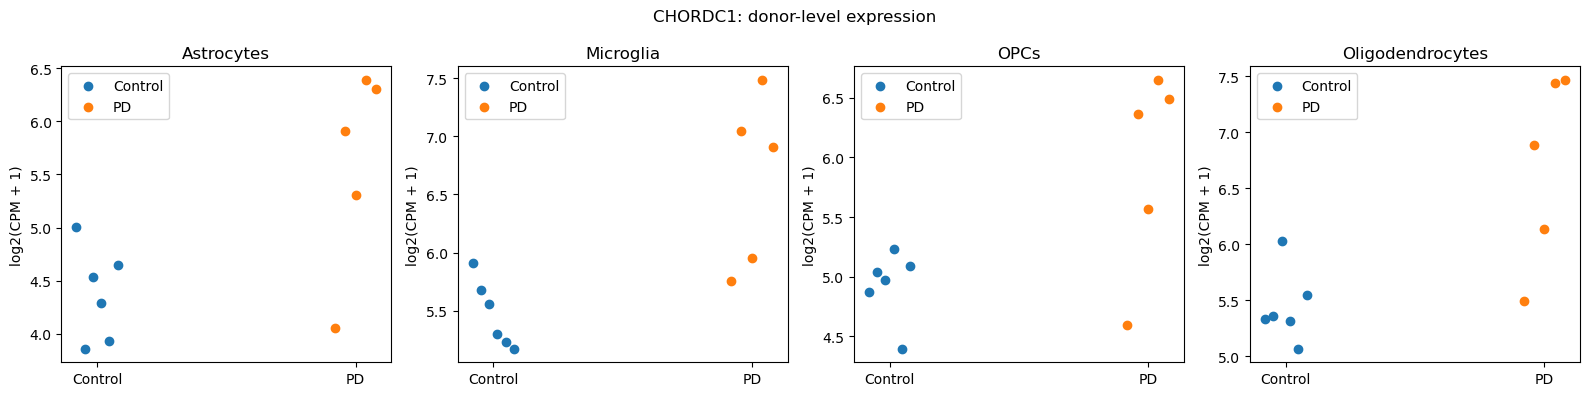

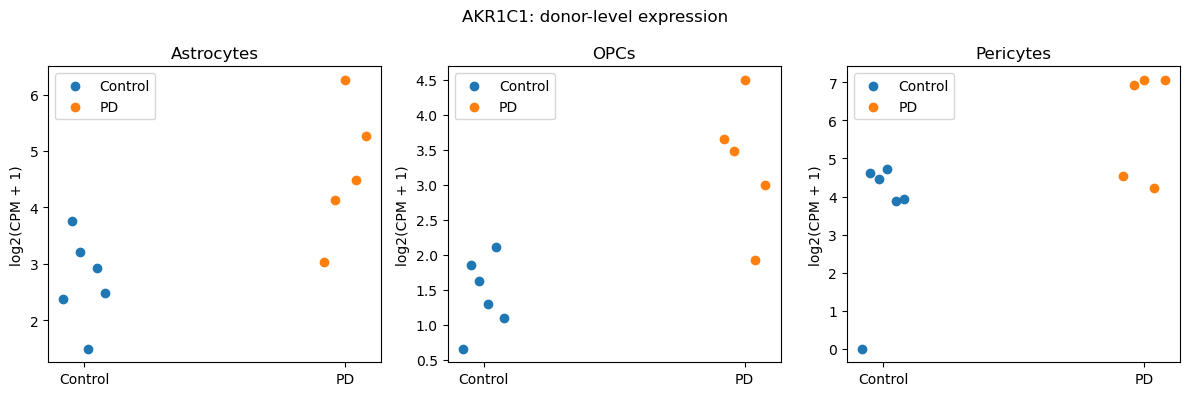

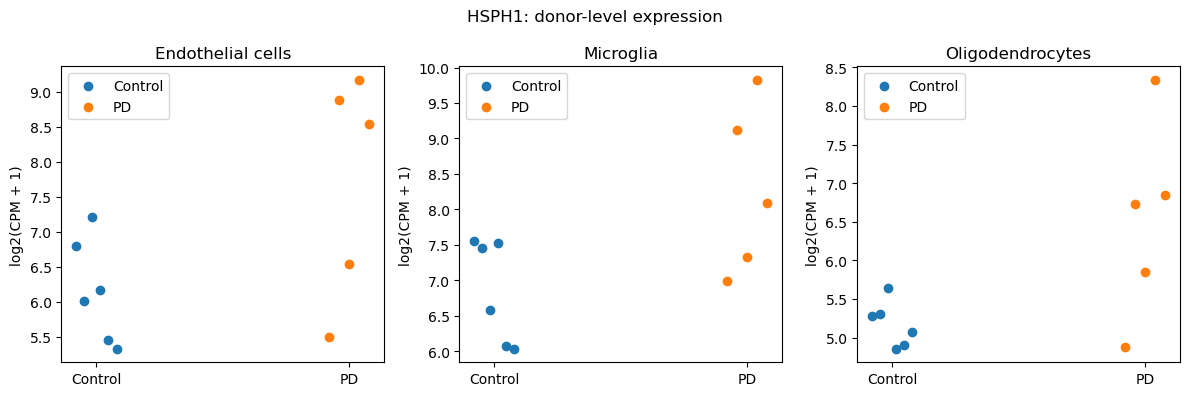

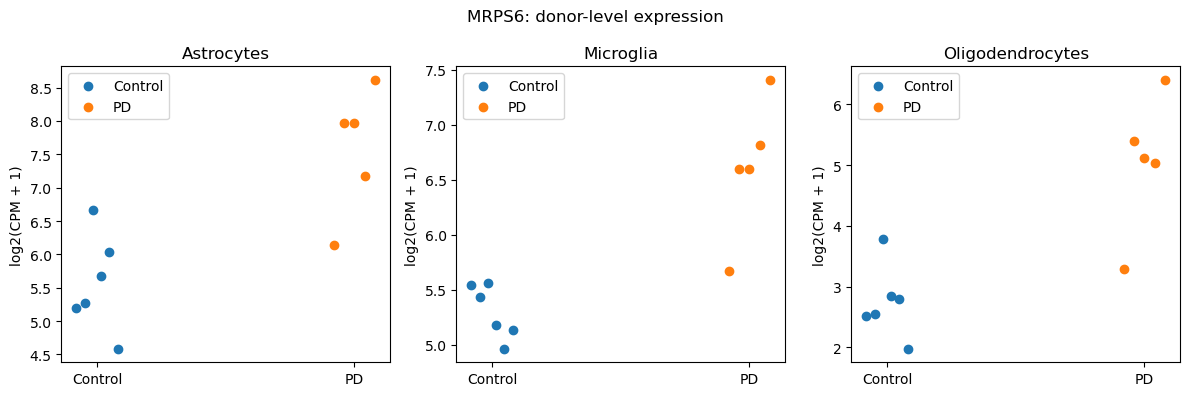

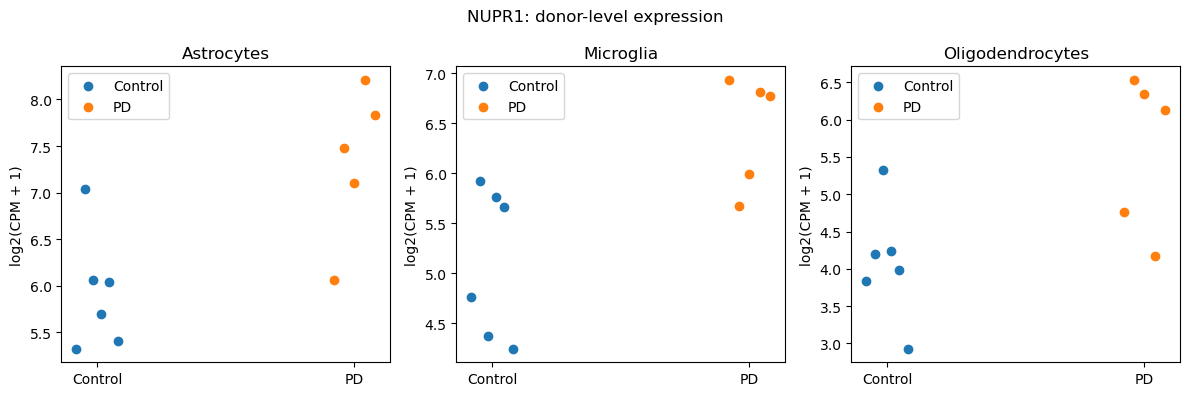

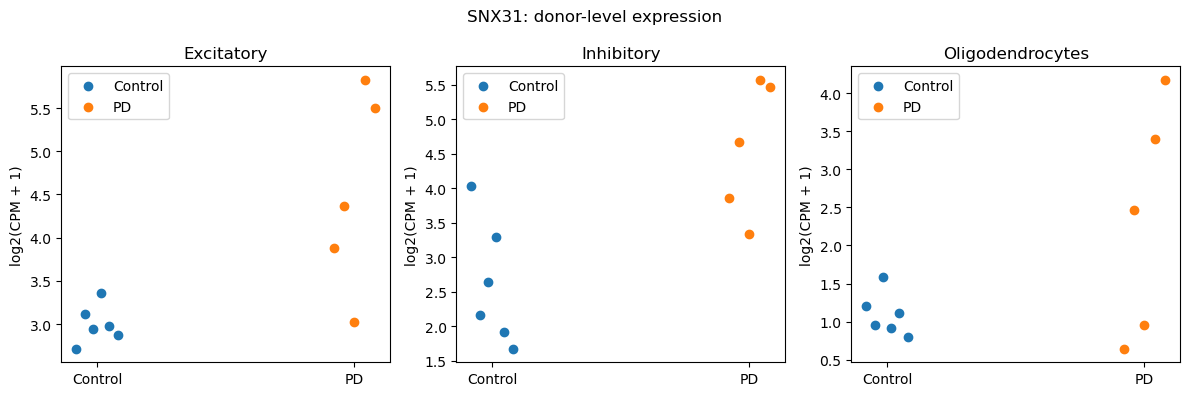

In [39]:
#Check donor-level expression

import matplotlib.pyplot as plt

candidate_symbols = [
    "MIR219A2HG", "CIRBP", "CHORDC1", "AKR1C1",
    "HSPH1", "MRPS6", "NUPR1", "SNX31"
]

plot_data = []

for _, row in candidate_results[
    candidate_results["symbol"].isin(candidate_symbols)
].drop_duplicates(["symbol", "cell_type"]).iterrows():

    gene_id = row["gene_id"]
    symbol = row["symbol"]
    cell_type = row["cell_type"]

    sample_meta = adata_pb.obs[
        adata_pb.obs["cell_ontology"] == cell_type
    ].copy()

    if gene_id not in adata_pb.var_names:
        continue

    sample_counts = adata_pb[sample_meta.index].layers["counts"]
    gene_counts = np.asarray(
        sample_counts[:, adata_pb.var_names.get_loc(gene_id)].toarray()
        if hasattr(sample_counts, "toarray")
        else sample_counts[:, adata_pb.var_names.get_loc(gene_id)]
    ).ravel()

    library_sizes = np.asarray(sample_counts.sum(axis=1)).ravel()

    # Log2 counts per million, for visualization only
    log_cpm = np.log2(
        (gene_counts / np.maximum(library_sizes, 1)) * 1_000_000 + 1
    )

    for sample_id, expression in zip(sample_meta.index, log_cpm):
        sample = sample_meta.loc[sample_id]
        plot_data.append({
            "gene": symbol,
            "cell_type": cell_type,
            "patient": sample["patient"],
            "condition": sample["condition"],
            "log2_CPM": expression
        })

plot_df = pd.DataFrame(plot_data)

for gene in candidate_symbols:
    gene_df = plot_df[plot_df["gene"] == gene]
    if gene_df.empty:
        continue

    cell_types = gene_df["cell_type"].unique()
    fig, axes = plt.subplots(
        1, len(cell_types),
        figsize=(4 * len(cell_types), 4),
        squeeze=False
    )

    for ax, ct in zip(axes.ravel(), cell_types):
        sub = gene_df[gene_df["cell_type"] == ct]

        for x, condition in enumerate(["Control", "PD"]):
            values = sub.loc[
                sub["condition"] == condition, "log2_CPM"
            ].to_numpy()

            # Show every donor separately
            jitter = np.linspace(-0.08, 0.08, len(values)) if len(values) else []
            ax.scatter(
                np.full(len(values), x) + jitter,
                values,
                label=condition
            )

        ax.set_xticks([0, 1], ["Control", "PD"])
        ax.set_title(ct)
        ax.set_ylabel("log2(CPM + 1)")
        ax.legend()

    fig.suptitle(f"{gene}: donor-level expression")
    plt.tight_layout()
    plt.show()


Your first-pass analysis produced the following numbers of significant candidate genes:
* Astrocytes: 211
* Endothelial cells: 11
* Excitatory neurons: 156
* Inhibitory neurons: 41
* Microglia: 385
* OPCs: 13
* Oligodendrocytes: 282
* Pericytes: 16
These are based on your selected thresholds of adjusted (p < 0.05) and (log2FC>1). We will retain these results but still need to check robustness before treating the candidates as reliable findings.

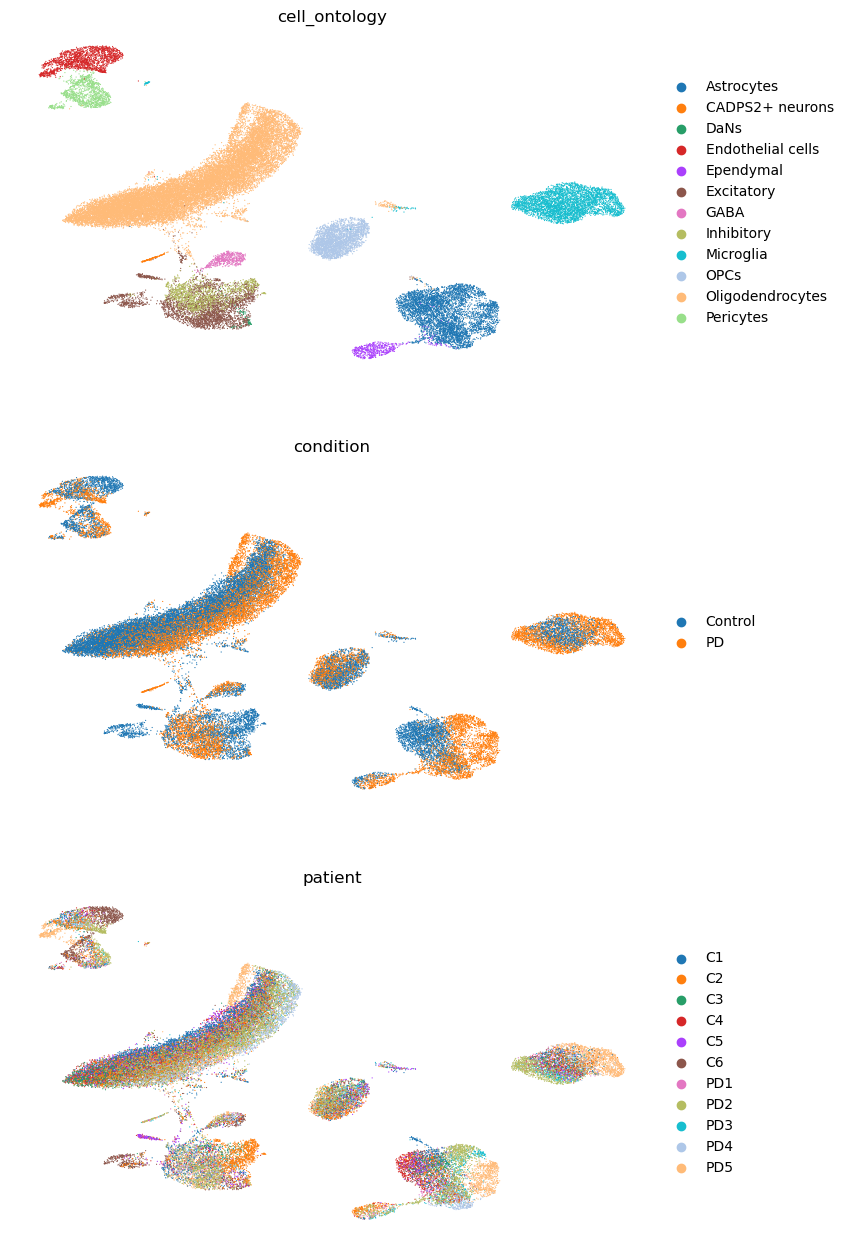

In [40]:
#View cell type, disease status, and donor identity

# Check that UMAP coordinates already exist
assert "X_umap" in adata_work.obsm, (
    "UMAP coordinates are missing. Recalculate neighbors and UMAP first."
)

# Plot the same UMAP colored in three different ways
sc.pl.umap(
    adata_work,
    color=["cell_ontology", "condition", "patient"],
    ncols=1,
    frameon=False,
    wspace=0.4
)


Cell type: identifies the different brain cell populations.

Condition: shows the distribution of Control and PD nuclei.

Patient/donor: shows which nuclei belong to C1–C6 and PD1–PD5, helping identify donor-specific patterns.

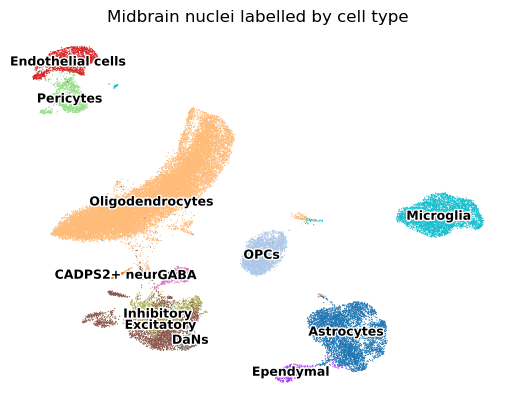

In [47]:
#Visualize expression of candidate genes on UMAP


import scanpy as sc
import matplotlib.pyplot as plt

sc.pl.umap(
    adata_work,
    color="cell_ontology",
    legend_loc="on data",
    legend_fontsize=9,
    legend_fontoutline=2,
    frameon=False,
    title="Midbrain nuclei labelled by cell type",
)



Genes available for plotting:


,symbol,gene_id
77,MIR219A2HG,ENSG00000207955
198,CIRBP,ENSG00000099622
133,CHORDC1,ENSG00000110172
68,AKR1C1,ENSG00000187134
218,HSPH1,ENSG00000120694
23,MRPS6,ENSG00000243927
121,NUPR1,ENSG00000176046
248,SNX31,ENSG00000174226


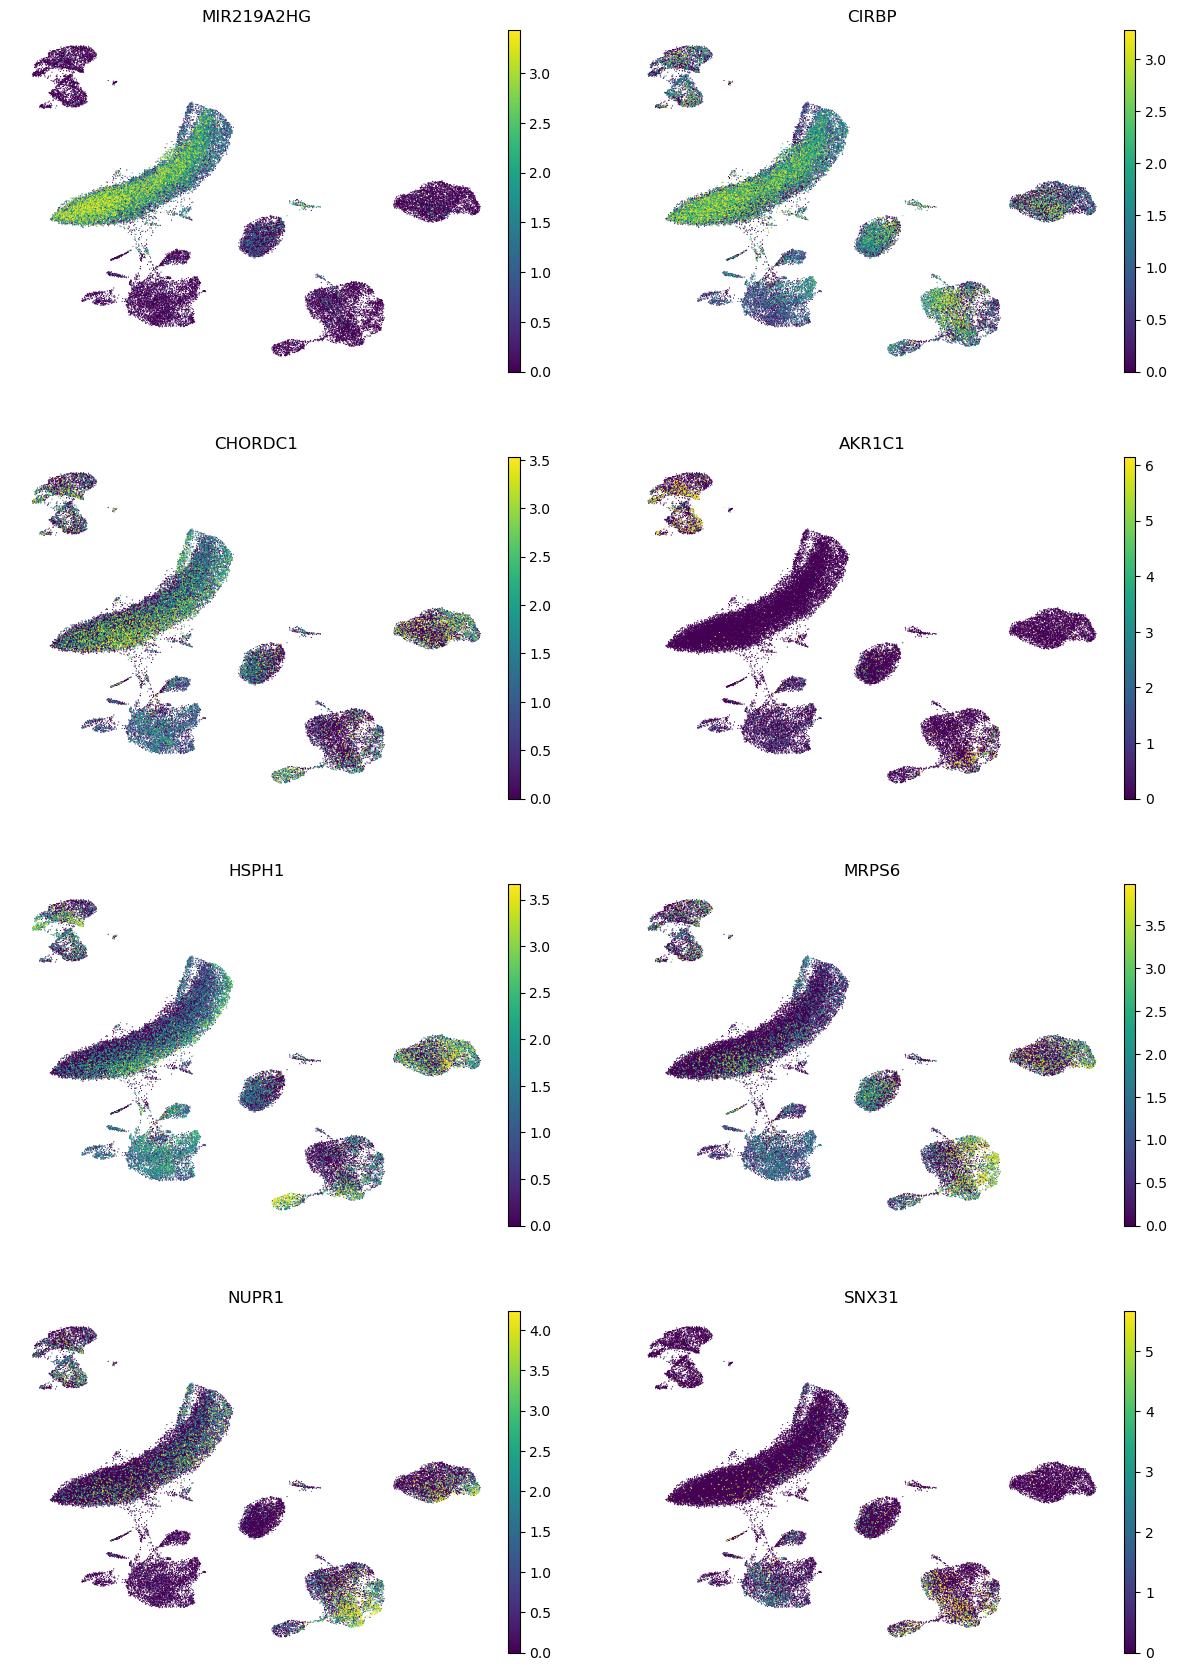

In [49]:
#UMAP expression plots for all eight candidate genes
candidate_symbols = [
    "MIR219A2HG",
    "CIRBP",
    "CHORDC1",
    "AKR1C1",
    "HSPH1",
    "MRPS6",
    "NUPR1",
    "SNX31"
]

# Get the symbol-to-Ensembl mapping from your existing results
gene_map = (
    significant_named[
        significant_named["symbol"].isin(candidate_symbols)
    ][["symbol", "gene_id"]]
    .dropna()
    .drop_duplicates()
)

# Keep only genes present in the expression matrix
gene_map = gene_map[
    gene_map["gene_id"].isin(adata_work.var_names)
].drop_duplicates("symbol")

# Preserve the requested order
gene_map["order"] = gene_map["symbol"].map(
    {symbol: i for i, symbol in enumerate(candidate_symbols)}
)
gene_map = gene_map.sort_values("order")

gene_ids = gene_map["gene_id"].tolist()
gene_titles = gene_map["symbol"].tolist()

print("Genes available for plotting:")
display(gene_map[["symbol", "gene_id"]])

# Plot all available candidate genes, with gene symbols as titles
sc.pl.umap(
    adata_work,
    color=gene_ids,
    title=gene_titles,
    ncols=2,
    frameon=False,
    use_raw=False,
    cmap="viridis",
    vmin=0,
    vmax="p99",
    colorbar_loc="right",
)


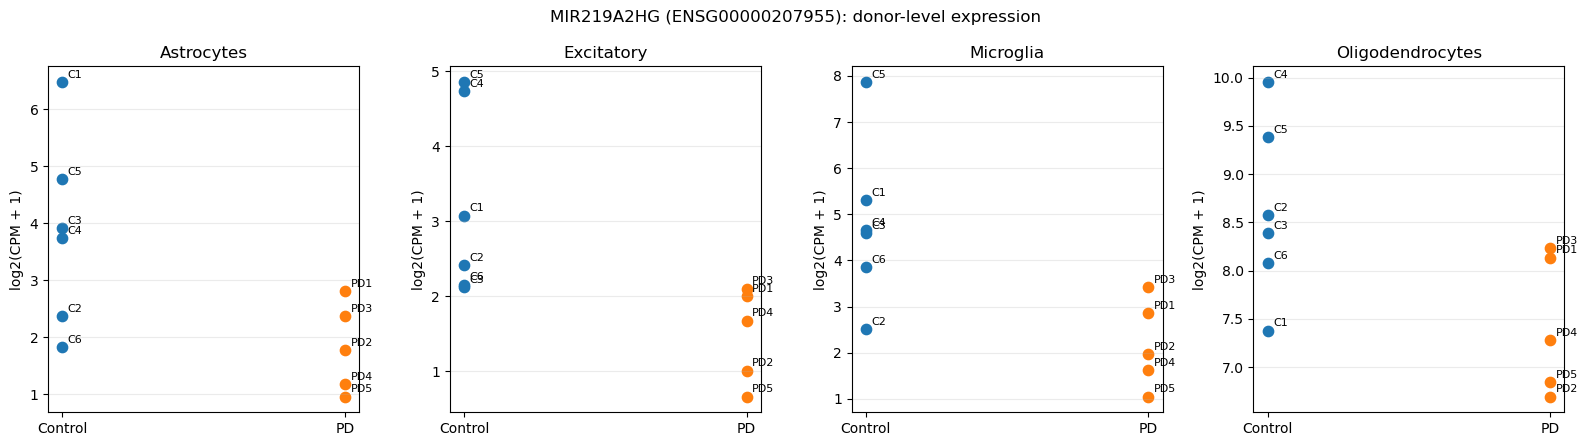

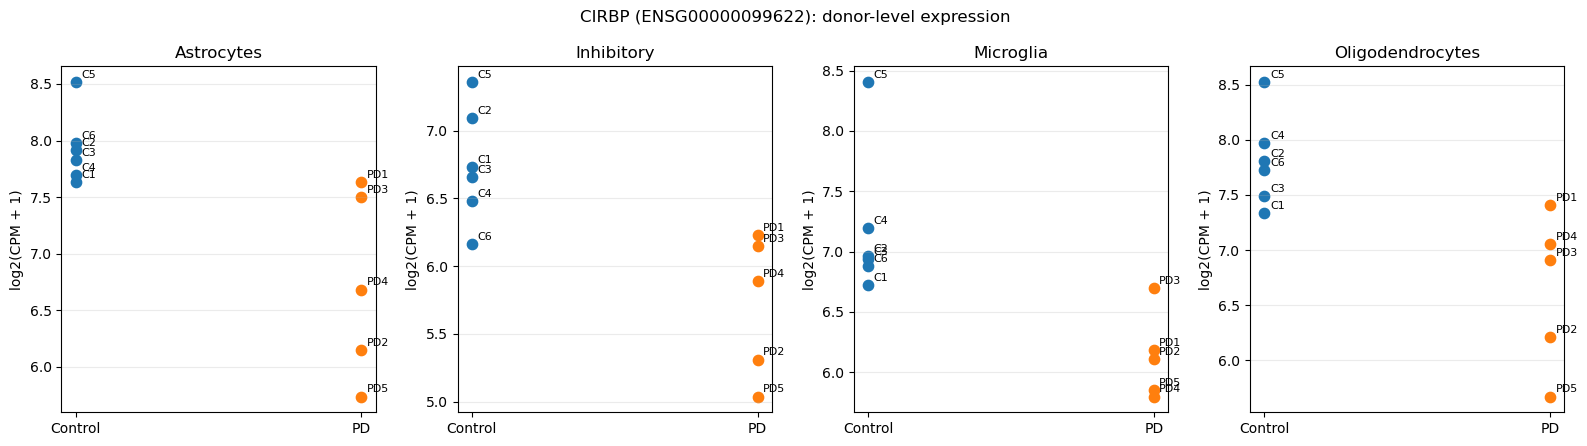

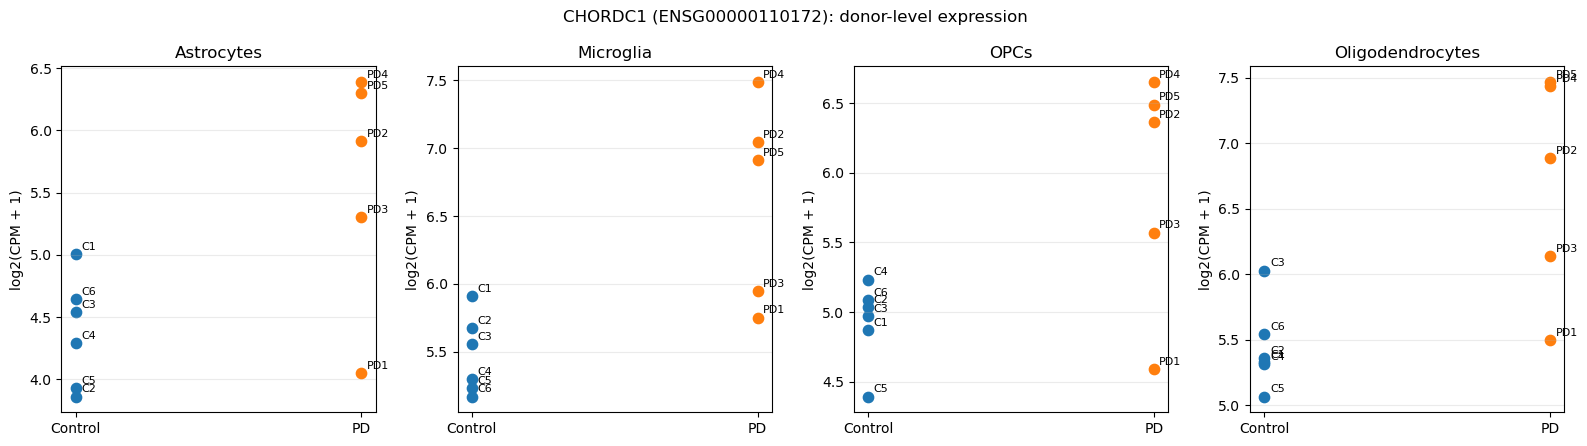

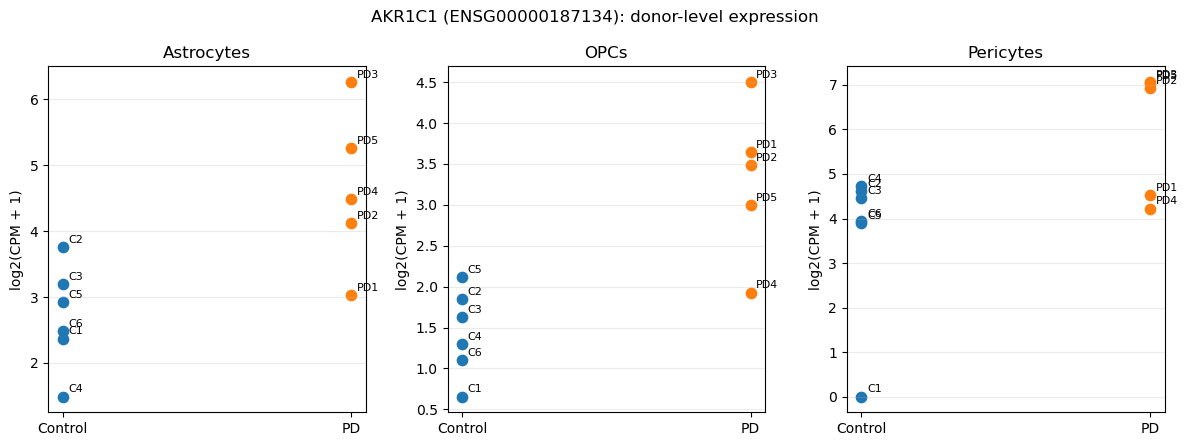

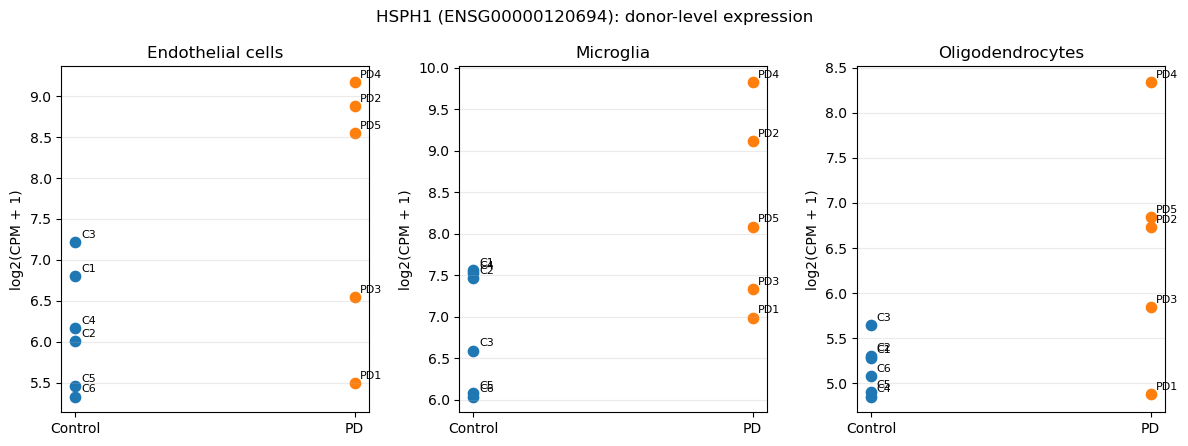

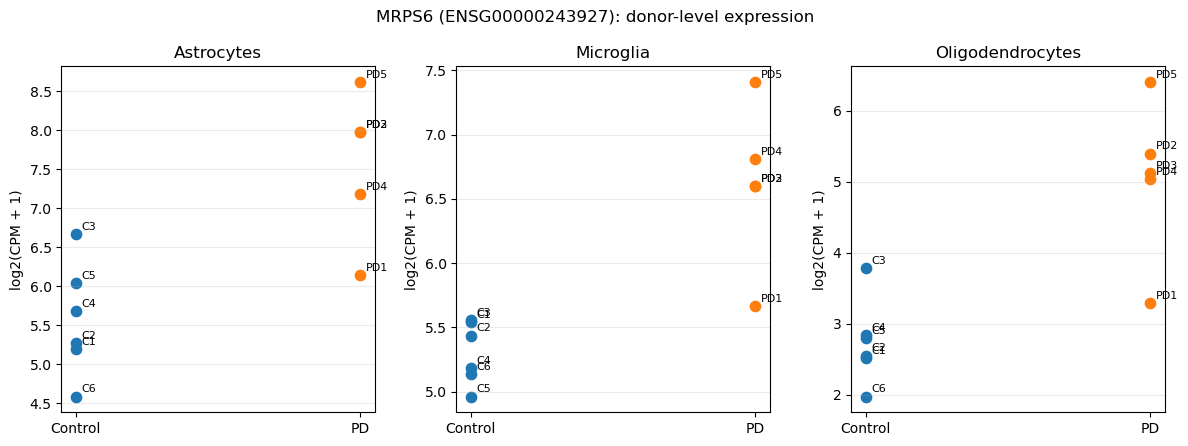

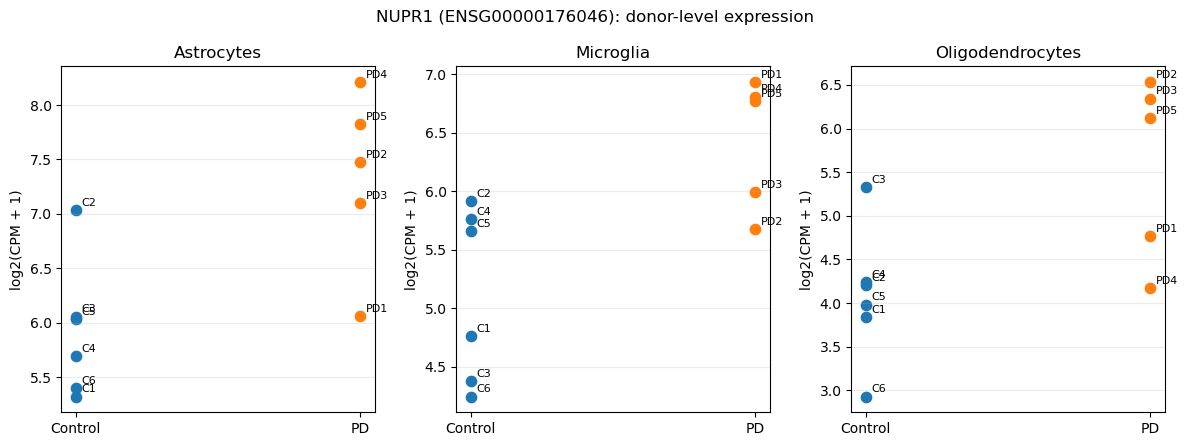

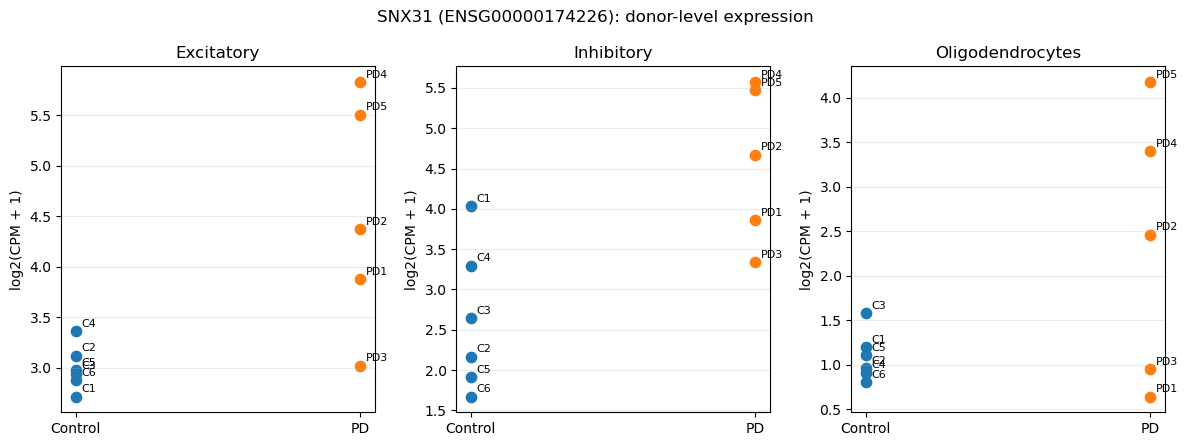

In [52]:
#Compare gene expression by disease status and donor

symbols = ["MIR219A2HG","CIRBP","CHORDC1","AKR1C1","HSPH1","MRPS6","NUPR1","SNX31" ]

# Use only significant gene-cell-type associations
gene_lookup = (
    candidate_results[
        candidate_results["symbol"].isin(symbols)
    ][["symbol", "gene_id", "cell_type"]]
    .drop_duplicates()
)

for symbol in symbols:
    gene_rows = gene_lookup[gene_lookup["symbol"] == symbol]

    if gene_rows.empty:
        print(f"No significant cell types found for {symbol}")
        continue

    gene_id = gene_rows.iloc[0]["gene_id"]

    if gene_id not in adata_pb.var_names:
        print(f"{gene_id} not found in pseudobulk matrix")
        continue

    # Raw pseudobulk counts for this gene across samples
    gene_idx = adata_pb.var_names.get_loc(gene_id)
    counts_matrix = adata_pb.layers["counts"]

    gene_counts = counts_matrix[:, gene_idx]
    if hasattr(gene_counts, "toarray"):
        gene_counts = gene_counts.toarray()
    gene_counts = np.asarray(gene_counts).ravel()

    # Total library size per pseudobulk sample
    library_sizes = np.asarray(
        counts_matrix.sum(axis=1)
    ).ravel()

    df = adata_pb.obs.copy()
    df["gene_counts"] = gene_counts
    df["library_size"] = library_sizes

    # Log2 counts per million, for visualization
    df["log2_CPM"] = np.log2(
        (df["gene_counts"] / np.maximum(df["library_size"], 1))
        * 1_000_000 + 1
    )

    # Only show cell types significant for this gene
    cell_types = gene_rows["cell_type"].unique().tolist()

    fig, axes = plt.subplots(
        1,
        len(cell_types),
        figsize=(max(5, 4 * len(cell_types)), 4.5),
        squeeze=False
    )

    for ax, cell_type in zip(axes.ravel(), cell_types):
        sub = df[df["cell_ontology"] == cell_type].copy()

        for x, condition in enumerate(["Control", "PD"]):
            group = sub[sub["condition"] == condition]

            ax.scatter(
                np.full(len(group), x),
                group["log2_CPM"],
                label=condition,
                s=55
            )

            # Label each point with its donor
            for _, sample in group.iterrows():
                ax.annotate(
                    str(sample["patient"]),
                    (x, sample["log2_CPM"]),
                    xytext=(4, 3),
                    textcoords="offset points",
                    fontsize=8
                )

        ax.set_xticks([0, 1], ["Control", "PD"])
        ax.set_title(cell_type)
        ax.set_ylabel("log2(CPM + 1)")
        ax.grid(axis="y", alpha=0.25)

    fig.suptitle(f"{symbol} ({gene_id}): donor-level expression")
    plt.tight_layout()
    plt.show()


In [53]:

from pathlib import Path
import json

# Dedicated folder for this brain dataset
project_dir = data_dir / "GSE157783_final"
project_dir.mkdir(parents=True, exist_ok=True)

# 1. Save original AnnData object, including raw counts and metadata
adata.write_h5ad(
    project_dir / "GSE157783_adata.h5ad",
    compression="gzip"
)

# 2. Save processed object if available
if "adata_work" in globals():
    adata_work.write_h5ad(
        project_dir / "GSE157783_processed.h5ad",
        compression="gzip"
    )

# 3. Save donor-level pseudobulk data
adata_pb.write_h5ad(
    project_dir / "GSE157783_pseudobulk.h5ad",
    compression="gzip"
)

# 4. Save full differential-expression results
combined_results.to_csv(
    project_dir / "GSE157783_all_DGE_results.csv",
    index=False
)

# 5. Save significant gene-cell-type associations with symbols
significant_named.to_csv(
    project_dir / "GSE157783_significant_genes.csv",
    index=False
)

# 6. Save recurrent candidate genes with symbols
recurrent_named.to_csv(
    project_dir / "GSE157783_recurrent_candidates.csv",
    index=False
)

# 7. Save priority candidate details
candidate_results.to_csv(
    project_dir / "GSE157783_priority_candidates.csv",
    index=False
)

# 8. Save the pseudobulk sample metadata
adata_pb.obs.to_csv(
    project_dir / "GSE157783_pseudobulk_metadata.csv"
)

# 9. Save the Ensembl-to-symbol mapping, if available
if "mapping_df" in globals():
    mapping_df.to_csv(
        project_dir / "GSE157783_gene_symbol_mapping.csv",
        index=False
    )

# 10. Save the donor-level cell counts by cell type
cell_number_table = adata_pb.obs.pivot(
    index="cell_ontology",
    columns="patient",
    values="n_nuclei"
).fillna(0).astype(int)

cell_number_table.to_csv(
    project_dir / "GSE157783_nuclei_per_donor_cell_type.csv"
)

# 11. Save a concise project summary
summary = {
    "GEO_accession": "GSE157783",
    "tissue": "Human midbrain",
    "assay": "snRNA-seq",
    "total_nuclei": int(adata.n_obs),
    "total_genes": int(adata.n_vars),
    "control_donors": 6,
    "PD_donors": 5,
    "primary_cell_types_analyzed": [
        "Astrocytes",
        "Endothelial cells",
        "Excitatory",
        "Inhibitory",
        "Microglia",
        "OPCs",
        "Oligodendrocytes",
        "Pericytes"
    ],
    "DGE_contrast": "PD versus Control",
    "significance_criteria": "adjusted p-value < 0.05 and absolute log2 fold change >= 1",
    "status": "First-pass analysis completed; robustness checks pending"
}

with open(
    project_dir / "GSE157783_analysis_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=2)

# 12. Print saved files and sizes
print("GSE157783 results saved to:")
print(project_dir.resolve())
print("\nSaved files:")

for file in sorted(project_dir.iterdir()):
    if file.is_file():
        size_mb = file.stat().st_size / (1024**2)
        print(f"{file.name} — {size_mb:.2f} MB")


GSE157783 results saved to:
C:\Users\LENOVO\Downloads\GSE157783\GSE157783_final

Saved files:
GSE157783_adata.h5ad — 513.41 MB
GSE157783_all_DGE_results.csv — 14.41 MB
GSE157783_analysis_summary.json — 0.00 MB
GSE157783_gene_symbol_mapping.csv — 0.05 MB
GSE157783_nuclei_per_donor_cell_type.csv — 0.00 MB
GSE157783_priority_candidates.csv — 0.01 MB
GSE157783_processed.h5ad — 860.71 MB
GSE157783_pseudobulk.h5ad — 14.22 MB
GSE157783_pseudobulk_metadata.csv — 0.01 MB
GSE157783_recurrent_candidates.csv — 0.08 MB
GSE157783_significant_genes.csv — 0.21 MB


GSE157783 Dataset preparation

-Loaded 41,435 nuclei and 26,737 genes; verified barcode matching and donor labels.


-QC and exploration: Calculated QC metrics and performed normalization, HVG selection, PCA, UMAP, and Leiden clustering.


-Cell-type analysis: Examined the dataset’s annotated cell types and cluster composition.


- Differential expression: Performed donor-level pseudobulk PD-versus-Control comparisons across eight primary cell types.


-Candidate identification: Generated significant gene lists, recurrent candidates, and Ensembl-to-symbol mappings.